imports and global vars

In [1]:
%pip install nltk seaborn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, re
from collections import Counter
import numpy as np
import nltk
import os

import torch
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.nn.utils import clip_grad_norm_
from torch.utils import data
from torch.utils.data import DataLoader, Dataset

import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../Data/data/en-US.jsonl"
GLOVE_PATH = "../Data/glove/glove.6B.300d.txt"
SLOT_REGEX = re.compile(r"\[([^\[\]:]+)\s*:\s*([^\[\]]+)\]")
UNK_TOKEN = "<UNK>"
PAD_TOKEN = "<PAD>"
HIDDEN_SIZE = 128
NUM_EPOCHS = 100
BATCH_SIZE = 50
LEARNING_RATE = 0.01
EMBEDDING_DIM = 300  # glove embedding are usually 50,100,200,300
SAVE_DIR = "../Results/"

load dataset functions

In [3]:
def parse_slots(annot_utt):
    # get list of (slot_type, slot_span) from annot_utt
    # turns the [color_type : pink] into ("color_type", "pink")
    return [(t.strip(), s.strip()) for t, s in SLOT_REGEX.findall(annot_utt)]

def load_massive(path=DATA_PATH):
    splits = {"train": [], "dev": [], "test": []}
    with open(path, encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            r = json.loads(line)
            splits[r["partition"]].append({
                "id": r["id"],
                "scenario": r["scenario"],
                "intent": r["intent"],
                "utt": r["utt"],
                "annot_utt": r["annot_utt"],
                "slots": parse_slots(r["annot_utt"]),  
            })
    return splits

split the dataset

In [4]:
splits = load_massive()
expected = {"train": 11514, "dev": 2033, "test": 2974}
for k, n in expected.items():
    print(f"{k}: {len(splits[k])}")
    assert len(splits[k]) == n
assert sum(len(v) for v in splits.values()) == 16521

intents = sorted({r["intent"] for v in splits.values() for r in v})
slotTypes = sorted({t for v in splits.values() for r in v for t, _ in r["slots"]})
print("intents:", len(intents), "| slot types:", len(slotTypes))
print(splits["train"][1])

train: 11514
dev: 2033
test: 2974
intents: 60 | slot types: 55
{'id': '2', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'set an alarm for two hours from now', 'annot_utt': 'set an alarm for [time : two hours from now]', 'slots': [('time', 'two hours from now')]}


preprocessing data

going with BIOES tagging for the parts of the sentence

In [5]:
def annot_to_bioes(annot_utt):
    """Convert annotated text into tokens and BIOES tags."""
    # use whitespace to split, so just do utt.split()
    # then assign tags based on the slots
    # theres 55 slot types, so they will be tagged as B-time, I-time, B-house_place that kind
    # the 55 types are defined in the above cell

    tokens = []
    tags = []
    position = 0

    # Process each annotated slot, such as [time : five am]
    for match in SLOT_REGEX.finditer(annot_utt):

        # Words outside a slot are tagged as O
        outsideText = annot_utt[position:match.start()]

        for word in outsideText.split():
            tokens.append(word)
            tags.append("O")

        slotType = match.group(1).strip()
        words = match.group(2).split()

        # Assign BIOES tag for each word 
        for i, word in enumerate(words):
            if len(words) == 1:
                tag = f"S-{slotType}"
            elif i == 0:
                tag = f"B-{slotType}"
            elif i == len(words) - 1:
                tag = f"E-{slotType}"
            else:
                tag = f"I-{slotType}"

            tokens.append(word)
            tags.append(tag)

        position = match.end()

    # Process any remaining words after the last slot
    for word in annot_utt[position:].split():
        tokens.append(word)
        tags.append("O")

    return tokens, tags


def build_tag_vocab(records):

    slotTypes = sorted({
        slotType
        for record in records
        for slotType, _ in record["slots"]
    })

    tags = ["O"]

    for slotType in slotTypes:
        for prefix in ("B", "I", "E", "S"):
            tags.append(f"{prefix}-{slotType}")

    tagToId = {tag: i for i, tag in enumerate(tags)}

    return tags, tagToId


Decode the BIOES tags into (slot_type, slot_span)

In [6]:
def decode_bioes(tokens, tags):
    """Convert BIOES tags into a list of (slotType, slotSpan) pairs."""
    # use whitespace to split, so just do utt.split()
    # then assign tags based on the slots
    # theres 55 slot types, so they will be tagged as B-time, I-time, B-house_place that kind
    # the 55 types are defined in the above cell
    
    spans = []
    currentType = None
    currentTokens = []

    def closeSpan():
        nonlocal currentType, currentTokens

        if currentType is not None:
            slotText = " ".join(currentTokens)
            spans.append((currentType, slotText))

        currentType = None
        currentTokens = []

    for token, tag in zip(tokens, tags):

        if tag == "O":
            closeSpan()
            continue

        prefix, slotType = tag.split("-", 1)

        if prefix == "B":
            closeSpan()
            currentType = slotType
            currentTokens = [token]

        elif prefix == "I":
            if currentType == slotType:
                currentTokens.append(token)
            else:
                closeSpan()
                currentType = slotType
                currentTokens = [token]

        elif prefix == "E":
            if currentType == slotType:
                currentTokens.append(token)
                closeSpan()
            else:
                closeSpan()
                spans.append((slotType, token))

        elif prefix == "S":
            closeSpan()
            spans.append((slotType, token))

        else:
            closeSpan()

    # Include any unfinished span at the end
    closeSpan()

    return spans

Evaluation functions

In [7]:
def eval_intent_accuracy(actual, predicted):
    """Calculate the percentage of correctly predicted intents."""

    assert len(actual) == len(predicted)

    correctCount = sum(
        gold == pred
        for gold, pred in zip(actual, predicted)
    )

    return 100.0 * correctCount / len(actual)

def eval_macro_f1(actual, predicted):
    """Calculate micro F1 for slot types and spans across all utterances."""

    assert len(actual) == len(predicted)

    truePositives = 0
    falsePositives = 0
    falseNegatives = 0

    for act, pred in zip(actual, predicted):
        actualCount = Counter(act)
        predCount= Counter(pred)

        matchedCount = sum((actualCount & predCount).values())

        truePositives += matchedCount
        falsePositives += sum(predCount.values()) - matchedCount
        falseNegatives += sum(actualCount.values()) - matchedCount

    denominator = (
        2 * truePositives
        + falsePositives
        + falseNegatives
    )

    if denominator == 0:
        return 0.0

    return 100.0 * 2 * truePositives / denominator

def evaluate(goldIntents, predIntents, goldSlots, predSlots):
    """Calculate and return intent accuracy and slot F1."""

    intentAcc = round(eval_intent_accuracy(goldIntents, predIntents), 2)

    slotF1 = round(eval_macro_f1(goldSlots, predSlots), 2)

    return {
        "intent_acc": intentAcc,
        "slot_f1": slotF1,
    }

---
# Stage 1: BiLSTM baseline (no attention)

**Pipeline**

| Part | Description |
|---|---|
| Input | the whitespace-tokenised `utt` only (lower-cased for the vocabulary lookup) |
| Embedding | 300-d GloVe vectors (word vectors are the only pretrained component allowed), fine-tuned during training |
| Encoder | 2-layer **bidirectional LSTM**, hidden size 128 per direction, dropout 0.3. No attention anywhere |
| Task 1 (intent) | final forward + backward hidden states of the top layer, concatenated (256-d), then a linear layer to 60 intents |
| Task 2 (slots) | per-token BiLSTM outputs (256-d), then a linear layer to 221 BIOES tags (`O` + 4 x 55 slot types) |
| Loss | `CE(intent) + CE(slot tags)` with padding ignored, i.e. joint multi-task training |
| Optimizer | Adam (lr = `LEARNING_RATE`), gradient-norm clipping at 5, `ReduceLROnPlateau` on the validation score |
| Regularisation | dropout on embeddings / LSTM / outputs, plus word-dropout (random tokens replaced by `<UNK>` during training) so that `<UNK>` is learned |
| Checkpoint | best epoch by validation combined score = (intent accuracy + slot micro-F1) / 2 |

Vocabulary is built from the **training split only**. At inference, slot tags are decoded back into `(slot_type, slot_span)` pairs with `decode_bioes`.

In [8]:
import time, random
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_packed_sequence
from torch.optim.lr_scheduler import ReduceLROnPlateau

SEED = 6769
NUM_LAYERS = 2
DROPOUT = 0.3
WORD_DROPOUT = 0.1
GRAD_CLIP = 5.0
PATIENCE = 15
IGNORE_INDEX = -100
BASELINE_CKPT = os.path.join(SAVE_DIR, "baseline_bilstm_best.pt")

os.makedirs(SAVE_DIR, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


### Build vocabularies and encode the data

* word vocabulary: **train split only** (lower-cased), plus `<PAD>`=0 and `<UNK>`=1
* intent vocabulary: the 60 intent labels
* tag vocabulary: `O` + `{B,I,E,S}-<slot_type>` for the 55 slot types (`build_tag_vocab`)

In [9]:
def get_tokens_and_tags(record):
    """Model input = utt tokens. Tags come from annot_utt (BIOES). If the annotation tokenisation ever
    differs from utt.split(), fall back to the annotation's own tokens (same words, so no label leakage)."""
    uttTokens = record["utt"].split()
    annotTokens, bioesTags = annot_to_bioes(record["annot_utt"])

    if len(uttTokens) == len(annotTokens):
        return uttTokens, bioesTags, False
    return annotTokens, bioesTags, True

def normalise_slots(slots):
    return [(t, " ".join(s.split())) for t, s in slots]

# handle vocab for words, intents, and tags
allRecords = [record for split in splits.values() for record in split]
tagList, tagToId = build_tag_vocab(allRecords)
idToTag = {tagId: tag for tag, tagId in tagToId.items()}
assert len(tagList) == 1 + 4 * len(slotTypes)

intentToId = {intent: i for i, intent in enumerate(intents)}
idToIntent = {i: intent for intent, i in intentToId.items()}

# word vocab (training split only, lower-cased)
wordCounter = Counter()
for record in splits["train"]:
    tokens, _, _ = get_tokens_and_tags(record)
    wordCounter.update(word.lower() for word in tokens)

idToWord = [PAD_TOKEN, UNK_TOKEN] + [word for word, _ in wordCounter.most_common()]
wordToId = {word: i for i, word in enumerate(idToWord)}
PAD_ID, UNK_ID = wordToId[PAD_TOKEN], wordToId[UNK_TOKEN]

print(f"word vocab: {len(wordToId)} | intents: {len(intentToId)} | tags: {len(tagToId)}")

# encode each split
def encode_split(records):
    """Turn raw records into model-ready examples. Returns (examples, numMismatches)."""
    examples = []
    numMismatches = 0

    for record in records:
        tokens, bioesTags, usedAnnotTokens = get_tokens_and_tags(record)
        numMismatches += usedAnnotTokens

        examples.append({
            "tokens": tokens,
            "ids": torch.tensor([wordToId.get(word.lower(), UNK_ID) for word in tokens], dtype=torch.long),
            "tags": torch.tensor([tagToId[tag] for tag in bioesTags], dtype=torch.long),
            "intent": intentToId[record["intent"]],
            "gold_slots": normalise_slots(record["slots"]),
        })

    return examples, numMismatches


encoded = {}
for splitName in ("train", "dev", "test"):
    encoded[splitName], numMismatches = encode_split(splits[splitName])

    isUnk = [
        wordToId.get(word.lower(), UNK_ID) == UNK_ID
        for example in encoded[splitName]
        for word in example["tokens"]
    ]
    oovRate = np.mean(isUnk) * 100
    print(f"{splitName}: {len(encoded[splitName])} examples | "
          f"utt/annot tokenisation mismatches: {numMismatches} | OOV token rate: {oovRate:.2f}%")

seqLengths = [len(example["tokens"]) for example in encoded["train"]]
print("train sequence length: mean %.1f, max %d" % (np.mean(seqLengths), max(seqLengths)))

word vocab: 5304 | intents: 60 | tags: 221
train: 11514 examples | utt/annot tokenisation mismatches: 0 | OOV token rate: 0.00%
dev: 2033 examples | utt/annot tokenisation mismatches: 0 | OOV token rate: 3.32%
test: 2974 examples | utt/annot tokenisation mismatches: 0 | OOV token rate: 3.51%
train sequence length: mean 6.9, max 35


In [10]:
# check that the encode-decode cycle matches with the gold slots
numBad = 0
for example in encoded["train"]:
    tagSeq = [idToTag[tagId.item()] for tagId in example["tags"]]
    decodedSlots = decode_bioes(example["tokens"], tagSeq)
    numBad += (decodedSlots != example["gold_slots"])

print("train examples where decode(encode(annot)) != gold slots:", numBad)
assert numBad == 0

train examples where decode(encode(annot)) != gold slots: 0


In [11]:
class NLUDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples
    def __len__(self):
        return len(self.examples)
    def __getitem__(self, i):
        return self.examples[i]

def collate_fn(batch):
    ids = pad_sequence([b["ids"] for b in batch], batch_first=True, padding_value=PAD_ID)
    tags = pad_sequence([b["tags"] for b in batch], batch_first=True, padding_value=IGNORE_INDEX)
    lengths = torch.tensor([len(b["ids"]) for b in batch], dtype=torch.long)
    intents_ = torch.tensor([b["intent"] for b in batch], dtype=torch.long)
    return ids, tags, lengths, intents_, [b["tokens"] for b in batch]

g = torch.Generator()
g.manual_seed(SEED)
trainLoader = DataLoader(NLUDataset(encoded["train"]), batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collate_fn, generator=g)
devLoader   = DataLoader(NLUDataset(encoded["dev"]),   batch_size=256, shuffle=False, collate_fn=collate_fn)
testLoader  = DataLoader(NLUDataset(encoded["test"]),  batch_size=256, shuffle=False, collate_fn=collate_fn)
print("batches/epoch:", len(trainLoader))

batches/epoch: 231


### Word embeddings (GloVe)

Only vocabulary words that appear in the **training** split are looked up in GloVe. Words not found in GloVe get a small random vector, and `<PAD>` is all zeros.
If `GLOVE_PATH` does not exist the notebook falls back to random initialisation and prints a warning, so make sure the printed coverage line below shows GloVe was actually loaded for the final run.

In [12]:
def load_glove_matrix(path, wordToId, dim):
    rng = np.random.RandomState(SEED)
    matrix = rng.normal(0, 0.3, size=(len(wordToId), dim)).astype(np.float32)
    matrix[PAD_ID] = 0.0
    
    if path is None or not os.path.exists(path):
        print(f"WARNING: GloVe file not found at {path}. Using random embeddings.")
        return torch.from_numpy(matrix), 0
    numFound = 0
    
    with open(path, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip().split(" ")
            w = parts[0]

            if w in wordToId and w not in (PAD_TOKEN, UNK_TOKEN) and len(parts) == dim + 1:
                matrix[wordToId[w]] = np.asarray(parts[1:], dtype=np.float32)
                numFound += 1
    
    coveragePct = 100 * numFound / len(wordToId)
    print(f"GloVe coverage: {numFound}/{len(wordToId)} vocab words ({coveragePct:.1f}%)")
    return torch.from_numpy(matrix), numFound

embedding_matrix, glove_found = load_glove_matrix(GLOVE_PATH, wordToId, EMBEDDING_DIM)

GloVe coverage: 4918/5304 vocab words (92.7%)


### Model: joint BiLSTM for intent classification + slot filling

`pack_padded_sequence` is used so the final hidden states (for the intent head) come from the true last token of every utterance, not from padding.

In [13]:
class BiLSTMJoint(nn.Module):
    def __init__(self, vocabSize, embDim, hiddenSize, numLayers, numIntents, numTags,
                 dropout, padIdx, pretrained=None):
        super().__init__()
        self.embedding = nn.Embedding(vocabSize, embDim, padding_idx=padIdx)
        if pretrained is not None:
            self.embedding.weight.data.copy_(pretrained)

        self.embDropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(embDim, hiddenSize, num_layers=numLayers, batch_first=True,
                            bidirectional=True, dropout=dropout if numLayers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)

        self.intentHead = nn.Linear(2 * hiddenSize, numIntents)
        self.slotHead = nn.Linear(2 * hiddenSize, numTags)
    
    def forward(self, ids, lengths):
        embedded = self.embDropout(self.embedding(ids))

        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packedOut, (finalHidden, _) = self.lstm(packed)
        seqOut, _ = pad_packed_sequence(packedOut, batch_first=True, total_length=ids.size(1))

        # top layer's final forward + backward hidden states
        sentenceRepr = torch.cat([finalHidden[-2], finalHidden[-1]], dim=-1)

        intentLogits = self.intentHead(self.dropout(sentenceRepr))
        slotLogits = self.slotHead(self.dropout(seqOut))
        return intentLogits, slotLogits

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def build_baseline():
    return BiLSTMJoint(len(wordToId), 
                       EMBEDDING_DIM, 
                       HIDDEN_SIZE, 
                       NUM_LAYERS, 
                       len(intentToId),
                       len(tagToId), 
                       DROPOUT, 
                       PAD_ID, 
                       pretrained=embedding_matrix
                       ).to(device)

set_seed()
baselineModel = build_baseline()
print(baselineModel)
baseTotal, baseTrainable = count_params(baselineModel)
print(f"\ntotal parameters: {baseTotal:,} | trainable: {baseTrainable:,}")

BiLSTMJoint(
  (embedding): Embedding(5304, 300, padding_idx=0)
  (embDropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(300, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (intentHead): Linear(in_features=256, out_features=60, bias=True)
  (slotHead): Linear(in_features=256, out_features=221, bias=True)
)

total parameters: 2,499,001 | trainable: 2,499,001


### Training / prediction utilities

`predict()` runs a split through the model (dropout off) and returns the losses, predicted intents and predicted `(slot_type, slot_span)` pairs. The scoring uses the shared `evaluate()` defined earlier. These helpers take the model as an argument so they can be reused unchanged in Stage 2.

In [14]:
def compute_losses(intentLogits, slotLogits, intentIds, tags):
    intentLoss = F.cross_entropy(intentLogits, intentIds)
    slotLoss = F.cross_entropy(
        slotLogits.reshape(-1, slotLogits.size(-1)),
        tags.reshape(-1),
        ignore_index=IGNORE_INDEX,
    )
    return intentLoss + slotLoss, intentLoss, slotLoss

def move_batch_to_device(ids, tags, lengths, intentIds):
    # send the batch tensors to the cpu for processing
    return ids.to(device), tags.to(device), lengths.to(device), intentIds.to(device)

@torch.no_grad()
def predict(model, loader):
    """Run a split through the model with dropout off.

    Returns a dict with the mean losses ("loss", "intent_loss", "slot_loss") and the predictions
    ("pred_intents", "pred_slots", "pred_tags").
    """
    model.eval()
    lossTotals = {"loss": 0.0, "intent_loss": 0.0, "slot_loss": 0.0}
    numBatches = 0
    predIntents, predSlots, predTags = [], [], []

    for ids, tags, lengths, intentIds, tokens in loader:
        ids, tags, lengths, intentIds = move_batch_to_device(ids, tags, lengths, intentIds)

        intentLogits, slotLogits = model(ids, lengths)
        loss, intentLoss, slotLoss = compute_losses(intentLogits, slotLogits, intentIds, tags)

        lossTotals["loss"] += loss.item()
        lossTotals["intent_loss"] += intentLoss.item()
        lossTotals["slot_loss"] += slotLoss.item()
        numBatches += 1

        # intents: one argmax per utterance
        predIntents += [idToIntent[intentId] for intentId in intentLogits.argmax(-1).tolist()]

        # slots: argmax per token, trimmed to the real length, then decoded into (type, span) pairs
        tagIdRows = slotLogits.argmax(-1).cpu().tolist()
        for utteranceTokens, tagIds in zip(tokens, tagIdRows):
            tagSeq = [idToTag[tagId] for tagId in tagIds[:len(utteranceTokens)]]
            predTags.append(tagSeq)
            predSlots.append(decode_bioes(utteranceTokens, tagSeq))

    output = {key: total / numBatches for key, total in lossTotals.items()}
    output.update(pred_intents=predIntents, pred_slots=predSlots, pred_tags=predTags)
    return output

def score_split(out, records_encoded):
    gold_intents = [idToIntent[e["intent"]] for e in records_encoded]
    gold_slots = [e["gold_slots"] for e in records_encoded]
    m = evaluate(gold_intents, out["pred_intents"], gold_slots, out["pred_slots"])
    m["combined"] = round((m["intent_acc"] + m["slot_f1"]) / 2, 2)
    return m

def apply_word_dropout(ids):
    """Randomly replace non-padding tokens with <UNK> so the model learns to cope with unseen words."""
    dropMask = (torch.rand_like(ids, dtype=torch.float) < WORD_DROPOUT) & (ids != PAD_ID)
    return ids.masked_fill(dropMask, UNK_ID)


def train_one_epoch(model, optimizer):
    """One pass over the training loader. Returns the epoch's mean total / intent / slot losses."""
    model.train()
    lossTotals = {"loss": 0.0, "intent_loss": 0.0, "slot_loss": 0.0}

    for ids, tags, lengths, intentIds, _ in trainLoader:
        ids, tags, lengths, intentIds = move_batch_to_device(ids, tags, lengths, intentIds)
        if WORD_DROPOUT > 0:
            ids = apply_word_dropout(ids)

        optimizer.zero_grad()
        intentLogits, slotLogits = model(ids, lengths)
        loss, intentLoss, slotLoss = compute_losses(intentLogits, slotLogits, intentIds, tags)
        loss.backward()
        clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        lossTotals["loss"] += loss.item()
        lossTotals["intent_loss"] += intentLoss.item()
        lossTotals["slot_loss"] += slotLoss.item()

    numBatches = len(trainLoader)
    return {key: total / numBatches for key, total in lossTotals.items()}


def train_model(model, ckptPath, numEpochs=NUM_EPOCHS, lr=LEARNING_RATE, patience=PATIENCE, tag="model"):
    """Train `model`, keeping the checkpoint with the best validation combined score.

    Stops early after `patience` epochs without improvement.
    Returns (history, best, totalTime): per-epoch records, best-epoch summary, total seconds.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # halve the learning rate when the validation score has not improved for 3 epochs
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

    history = []
    best = {"score": -1.0, "epoch": 0}
    badEpochs = 0
    startTime = time.time()

    for epoch in range(1, numEpochs + 1):
        epochStart = time.time()

        trainLosses = train_one_epoch(model, optimizer)

        valOut = predict(model, devLoader)
        valMetrics = score_split(valOut, encoded["dev"])
        scheduler.step(valMetrics["combined"])

        record = {
            "epoch": epoch,
            "train_loss": trainLosses["loss"],
            "train_intent_loss": trainLosses["intent_loss"],
            "train_slot_loss": trainLosses["slot_loss"],
            "val_loss": valOut["loss"],
            "val_intent_loss": valOut["intent_loss"],
            "val_slot_loss": valOut["slot_loss"],
            "val_intent_acc": valMetrics["intent_acc"],
            "val_slot_f1": valMetrics["slot_f1"],
            "val_score": valMetrics["combined"],
            "lr": optimizer.param_groups[0]["lr"],
            "epoch_time": time.time() - epochStart,
            "elapsed": time.time() - startTime,
        }
        history.append(record)

        # checkpoint whenever the validation combined score improves
        improved = valMetrics["combined"] > best["score"]
        if improved:
            best = {"score": valMetrics["combined"], "epoch": epoch, "metrics": valMetrics}
            badEpochs = 0
            torch.save({
                "model_state": model.state_dict(),
                "epoch": epoch,
                "val_score": valMetrics["combined"],
                "val_metrics": valMetrics,
            }, ckptPath)
        else:
            badEpochs += 1

        savedMarker = "  <- saved" if improved else ""
        print(f"[{tag}] epoch {epoch:3d} | train loss {record['train_loss']:.4f} | val loss {record['val_loss']:.4f} | "
              f"val intent acc {valMetrics['intent_acc']:6.2f} | val slot F1 {valMetrics['slot_f1']:6.2f} | "
              f"score {valMetrics['combined']:6.2f} | lr {record['lr']:.5f} | {record['epoch_time']:.1f}s"
              f"{savedMarker}")

        if badEpochs >= patience:
            print(f"early stopping: no improvement for {patience} epochs")
            break

    totalTime = time.time() - startTime
    print(f"\ntraining finished: {len(history)} epochs in {totalTime:.1f}s")
    print(f"best epoch: {best['epoch']} | best validation score: {best['score']:.2f} "
          f"(intent acc {best['metrics']['intent_acc']:.2f}, slot F1 {best['metrics']['slot_f1']:.2f}) | "
          f"checkpoint: {ckptPath}")
    return history, best, totalTime

### Train the baseline (training split only; validation split used for model selection)

In [15]:
set_seed()
baselineModel = build_baseline()
baselineHistory, baselineBest, baselineTime = train_model(baselineModel, BASELINE_CKPT, tag="BiLSTM baseline")

[BiLSTM baseline] epoch   1 | train loss 3.4935 | val loss 1.4769 | val intent acc  75.26 | val slot F1  55.47 | score  65.37 | lr 0.01000 | 5.6s  <- saved
[BiLSTM baseline] epoch   2 | train loss 1.6591 | val loss 1.1821 | val intent acc  80.82 | val slot F1  63.14 | score  71.98 | lr 0.01000 | 5.5s  <- saved
[BiLSTM baseline] epoch   3 | train loss 1.3343 | val loss 1.0897 | val intent acc  83.13 | val slot F1  67.74 | score  75.44 | lr 0.01000 | 5.2s  <- saved
[BiLSTM baseline] epoch   4 | train loss 1.1854 | val loss 1.1107 | val intent acc  82.10 | val slot F1  66.48 | score  74.29 | lr 0.01000 | 5.2s
[BiLSTM baseline] epoch   5 | train loss 1.1020 | val loss 1.1133 | val intent acc  81.80 | val slot F1  66.70 | score  74.25 | lr 0.01000 | 5.3s
[BiLSTM baseline] epoch   6 | train loss 1.0741 | val loss 1.0903 | val intent acc  82.83 | val slot F1  67.46 | score  75.14 | lr 0.01000 | 5.3s
[BiLSTM baseline] epoch   7 | train loss 1.0690 | val loss 1.0915 | val intent acc  83.92 | va

### Learning curves

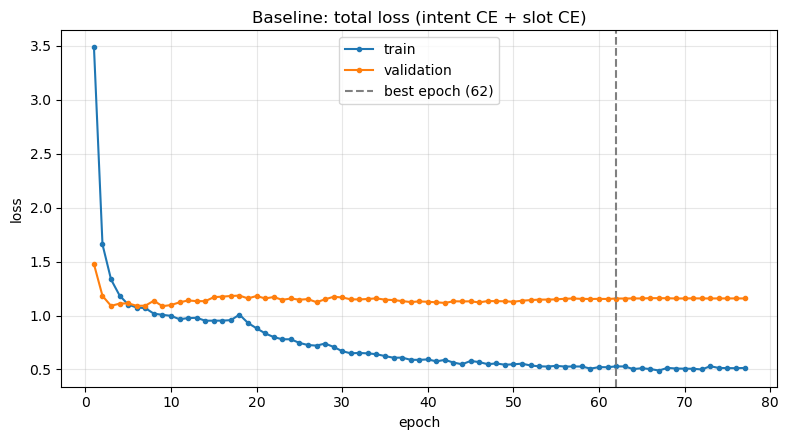

In [16]:
def get_history_values(history, key):
    """Pull one metric out of the per-epoch history as a list."""
    return [record[key] for record in history]


def plot_curve(history, series, title, ylabel, bestEpoch=None):
    """Plot one or more history metrics against epoch, optionally marking the best epoch.

    `series` is a list of (historyKey, legendLabel) pairs.
    """
    plt.figure(figsize=(8, 4.5))
    epochs = get_history_values(history, "epoch")

    for key, label in series:
        plt.plot(epochs, get_history_values(history, key), label=label, marker="o", markersize=3)

    if bestEpoch is not None:
        plt.axvline(bestEpoch, color="gray", linestyle="--", label=f"best epoch ({bestEpoch})")

    plt.title(title)
    plt.xlabel("epoch")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_curve(
    baselineHistory,
    [("train_loss", "train"), ("val_loss", "validation")],
    "Baseline: total loss (intent CE + slot CE)",
    "loss",
    baselineBest["epoch"],
)

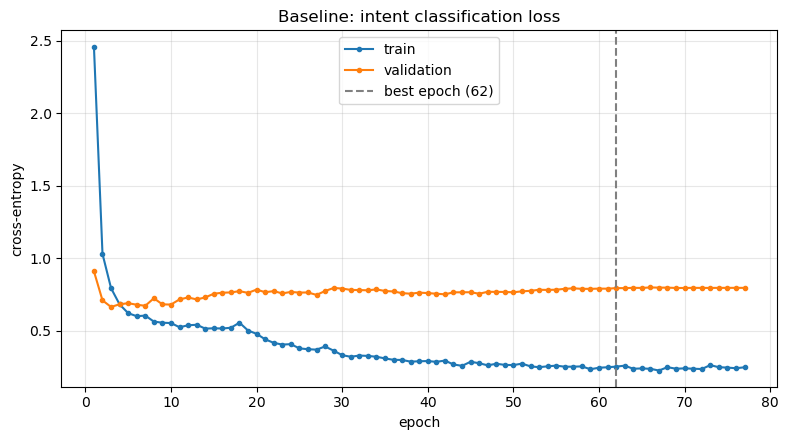

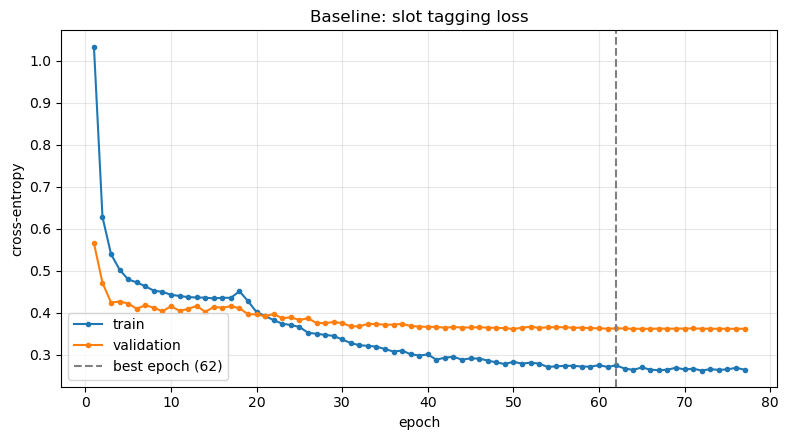

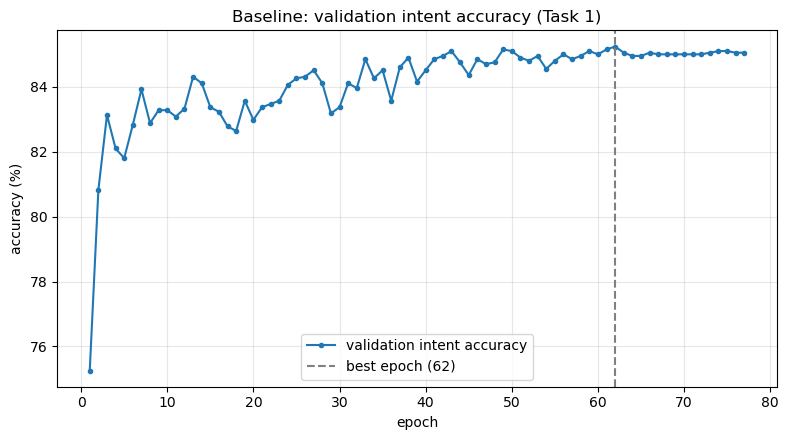

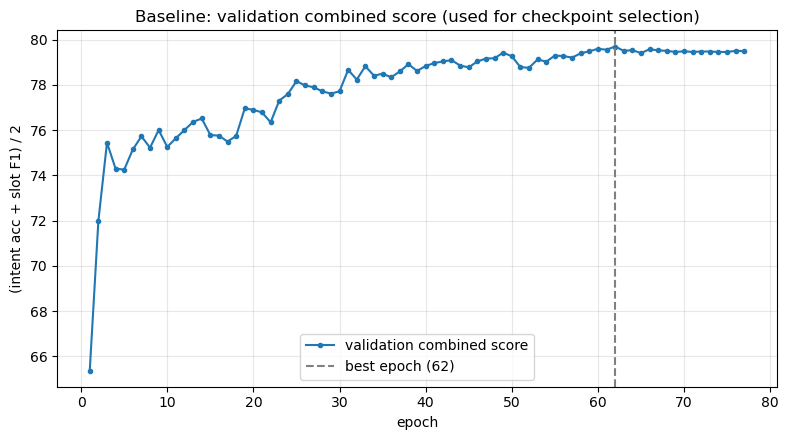

In [17]:
plot_curve(
    baselineHistory,
    [("train_intent_loss", "train"), ("val_intent_loss", "validation")],
    "Baseline: intent classification loss",
    "cross-entropy",
    baselineBest["epoch"],
)

plot_curve(
    baselineHistory,
    [("train_slot_loss", "train"), ("val_slot_loss", "validation")],
    "Baseline: slot tagging loss",
    "cross-entropy",
    baselineBest["epoch"],
)

plot_curve(
    baselineHistory,
    [("val_intent_acc", "validation intent accuracy")],
    "Baseline: validation intent accuracy (Task 1)",
    "accuracy (%)",
    baselineBest["epoch"],
)

plot_curve(
    baselineHistory,
    [("val_score", "validation combined score")],
    "Baseline: validation combined score (used for checkpoint selection)",
    "(intent acc + slot F1) / 2",
    baselineBest["epoch"],
)

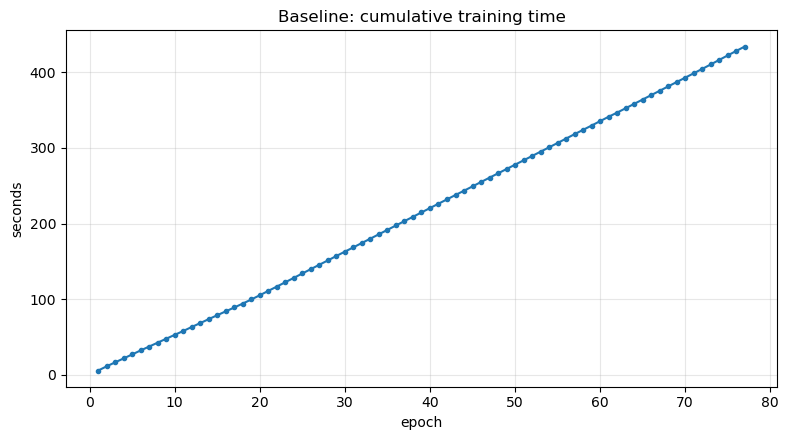

In [18]:
plt.figure(figsize=(8, 4.5))
plt.plot(get_history_values(baselineHistory, "epoch"),
         get_history_values(baselineHistory, "elapsed"),
         marker="o", markersize=3)
plt.title("Baseline: cumulative training time")
plt.xlabel("epoch")
plt.ylabel("seconds")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Final evaluation of the baseline checkpoint

The best checkpoint is loaded into a **freshly built** model (no further training) and evaluated on the validation and test splits. The validation scores must equal the best validation score recorded during training.

In [19]:
def final_evaluation(ckptPath, history, best, trainTime, label, buildFn=build_baseline):
    model = buildFn()
    checkpoint = torch.load(ckptPath, map_location=device)
    model.load_state_dict(checkpoint["model_state"])
    totalParams, trainableParams = count_params(model)
    print(f"loaded {ckptPath} (saved at epoch {checkpoint['epoch']})")

    valOut = predict(model, devLoader)
    valMetrics = score_split(valOut, encoded["dev"])
    testOut = predict(model, testLoader)
    testMetrics = score_split(testOut, encoded["test"])

    # validation score must reproduce the best score recorded during training
    assert abs(valMetrics["combined"] - best["score"]) < 0.01, (valMetrics, best)
    assert abs(valMetrics["intent_acc"] - best["metrics"]["intent_acc"]) < 0.01
    assert abs(valMetrics["slot_f1"] - best["metrics"]["slot_f1"]) < 0.01
    print("validation scores reproduce the best training-time score")

    print(f"\n{label} | total params {totalParams:,} | trainable {trainableParams:,} | "
          f"best epoch {checkpoint['epoch']} | epochs run {len(history)}")
    print(f"  VALIDATION  intent accuracy: {valMetrics['intent_acc']:.2f}% | slot micro-F1: {valMetrics['slot_f1']:.2f}%")
    print(f"  TEST        intent accuracy: {testMetrics['intent_acc']:.2f}% | slot micro-F1: {testMetrics['slot_f1']:.2f}%")

    results = {
        "label": label,
        "total_params": totalParams,
        "trainable_params": trainableParams,
        "best_epoch": checkpoint["epoch"],
        "epochs_run": len(history),
        "train_time_s": trainTime,
        "validation": {key: valMetrics[key] for key in ("intent_acc", "slot_f1")},
        "test": {key: testMetrics[key] for key in ("intent_acc", "slot_f1")},
    }
    return model, valOut, testOut, results


baselineModel, baseValOut, baseTestOut, baselineResults = final_evaluation(
    BASELINE_CKPT, baselineHistory, baselineBest, baselineTime, "Stage-1 BiLSTM baseline")

with open(os.path.join(SAVE_DIR, "baseline_results.json"), "w") as resultsFile:
    json.dump(baselineResults, resultsFile, indent=2)
with open(os.path.join(SAVE_DIR, "baseline_history.json"), "w") as historyFile:
    json.dump(baselineHistory, historyFile, indent=2)

loaded ../Results/baseline_bilstm_best.pt (saved at epoch 62)
validation scores reproduce the best training-time score

Stage-1 BiLSTM baseline | total params 2,499,001 | trainable 2,499,001 | best epoch 62 | epochs run 77
  VALIDATION  intent accuracy: 85.24% | slot micro-F1: 74.14%
  TEST        intent accuracy: 84.70% | slot micro-F1: 71.21%


In [20]:
# row format used in the report's comparison table
print(f"{'Model version':<16}{'Split':<12}{'#params':>12}{'#trainable':>12}{'Intent acc':>12}{'Slot F1':>10}{'Epochs':>8}")
for split in ("validation", "test"):
    metrics = baselineResults[split]
    print(f"{'Stage-1 system':<16}{split.capitalize():<12}"
          f"{baselineResults['total_params']:>12,}{baselineResults['trainable_params']:>12,}"
          f"{metrics['intent_acc']:>12.2f}{metrics['slot_f1']:>10.2f}{baselineResults['epochs_run']:>8}")

Model version   Split            #params  #trainable  Intent acc   Slot F1  Epochs
Stage-1 system  Validation     2,499,001   2,499,001       85.24     74.14      77
Stage-1 system  Test           2,499,001   2,499,001       84.70     71.21      77


### Baseline analysis (test split)

Per-task breakdowns to see where the BiLSTM fails: per-scenario intent accuracy, the most confused intent pairs, per-slot-type F1 and concrete error cases (useful for the report's error analysis).

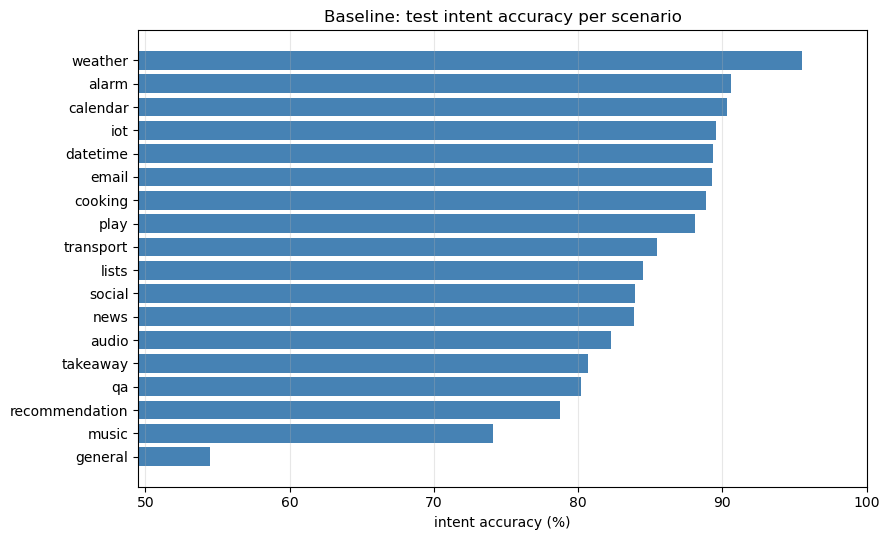

In [21]:
testGoldIntents = [idToIntent[example["intent"]] for example in encoded["test"]]
testPredIntents = baseTestOut["pred_intents"]
scenarioOf = {record["intent"]: record["scenario"] for split in splits.values() for record in split}

scenarioCorrect, scenarioTotal = Counter(), Counter()
for goldIntent, predIntent in zip(testGoldIntents, testPredIntents):
    scenario = scenarioOf[goldIntent]
    scenarioTotal[scenario] += 1
    scenarioCorrect[scenario] += (goldIntent == predIntent)

scenarioAcc = {scenario: 100 * scenarioCorrect[scenario] / scenarioTotal[scenario] for scenario in scenarioTotal}
scenariosByAcc = sorted(scenarioAcc, key=scenarioAcc.get)

plt.figure(figsize=(9, 5.5))
plt.barh(scenariosByAcc, [scenarioAcc[scenario] for scenario in scenariosByAcc], color="steelblue")
plt.xlabel("intent accuracy (%)")
plt.title("Baseline: test intent accuracy per scenario")
plt.xlim(min(scenarioAcc.values()) - 5, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

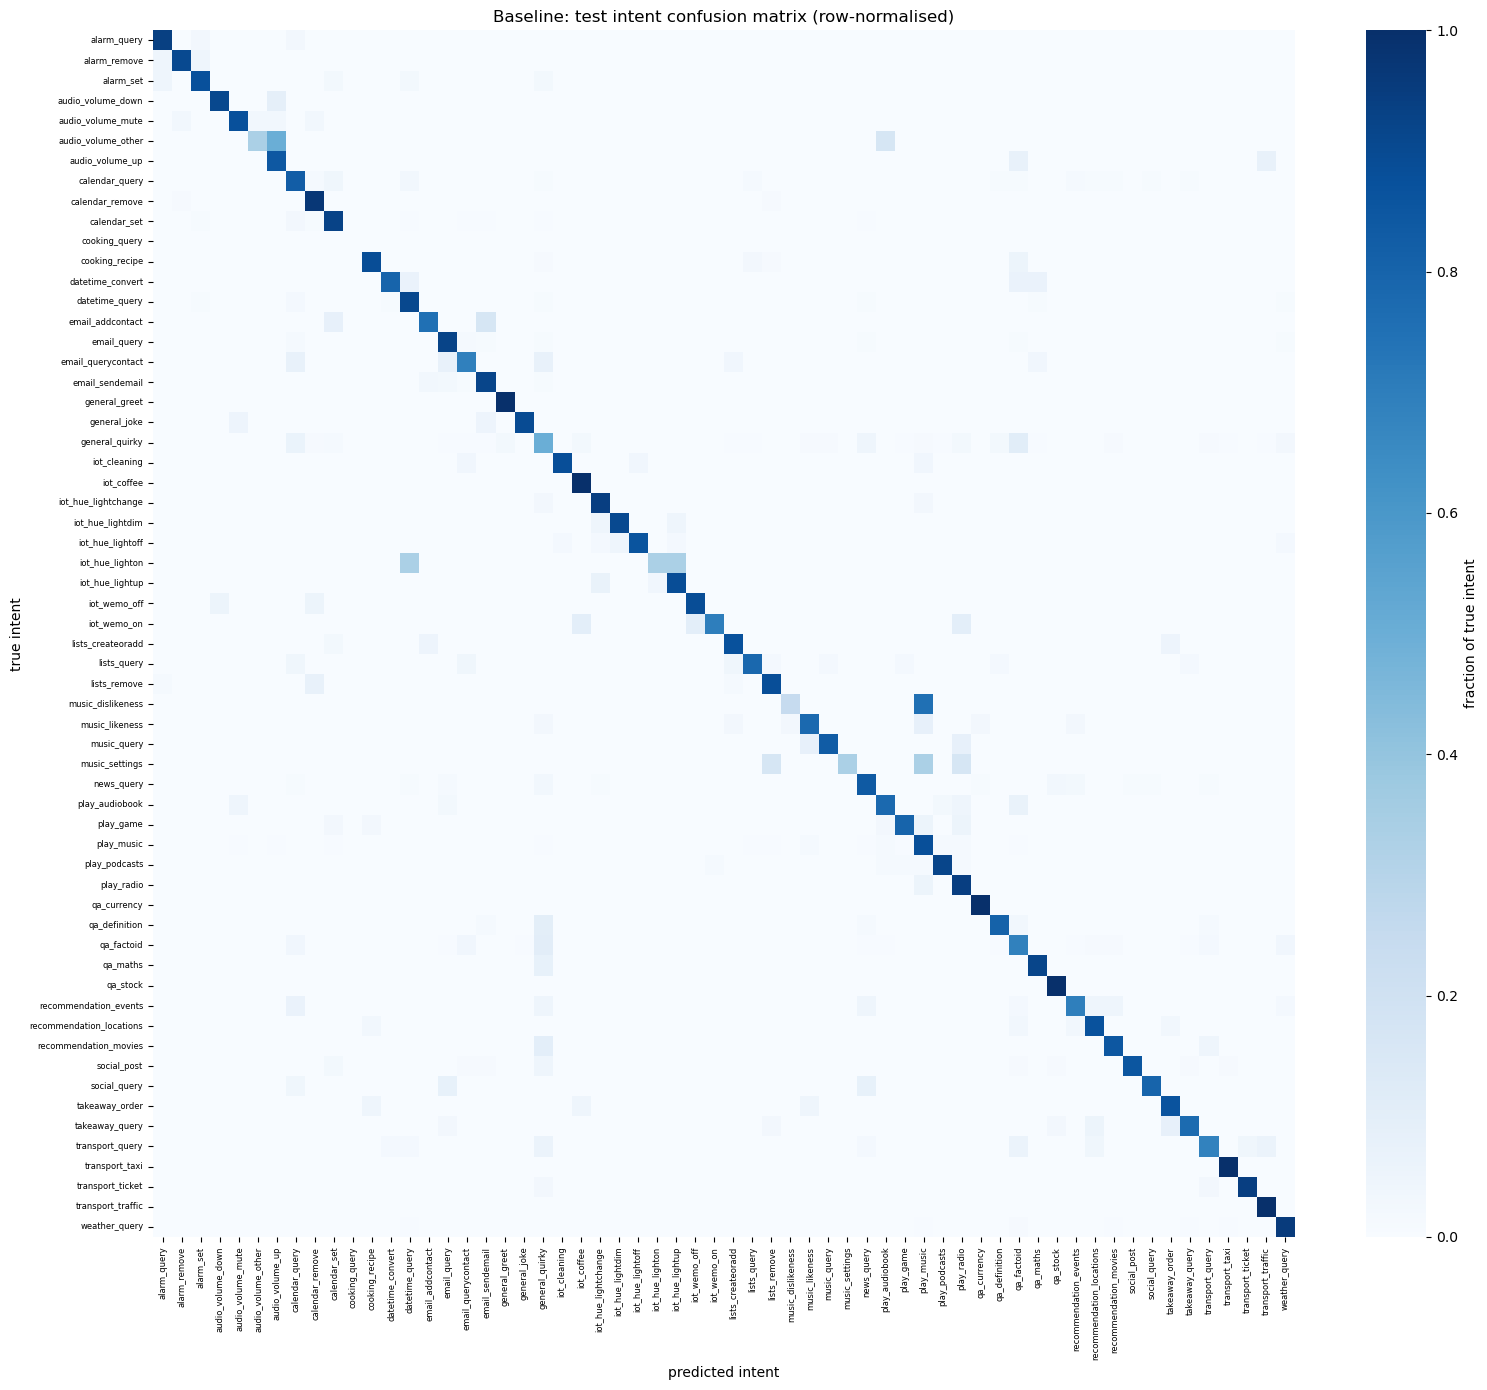

most confused intent pairs (count, true -> predicted):
   19  general_quirky  ->  qa_factoid
   15  qa_factoid  ->  general_quirky
   11  general_quirky  ->  calendar_query
    8  general_quirky  ->  news_query
    6  qa_definition  ->  general_quirky
    6  calendar_set  ->  calendar_query
    5  qa_factoid  ->  weather_query
    5  qa_factoid  ->  email_querycontact
    5  qa_factoid  ->  calendar_query
    5  general_quirky  ->  weather_query
    5  calendar_query  ->  calendar_set
    4  social_post  ->  general_quirky


In [22]:
# confusion matrix over the 60 intents (row-normalised)
numIntents = len(intents)
confusionCounts = np.zeros((numIntents, numIntents), dtype=int)
for goldIntent, predIntent in zip(testGoldIntents, testPredIntents):
    confusionCounts[intentToId[goldIntent], intentToId[predIntent]] += 1
confusionNorm = confusionCounts / confusionCounts.sum(axis=1, keepdims=True).clip(min=1)

plt.figure(figsize=(16, 14))
sns.heatmap(confusionNorm, 
            xticklabels=intents, 
            yticklabels=intents, 
            cmap="Blues", 
            vmin=0, vmax=1,
            cbar_kws={"label": "fraction of true intent"}
            )

plt.xticks(fontsize=6, rotation=90)
plt.yticks(fontsize=6)
plt.xlabel("predicted intent")
plt.ylabel("true intent")
plt.title("Baseline: test intent confusion matrix (row-normalised)")
plt.tight_layout()
plt.show()

# top confused pairs
offDiagonal = [
    (confusionCounts[i, j], intents[i], intents[j])
    for i in range(numIntents)
    for j in range(numIntents)
    if i != j and confusionCounts[i, j] > 0
]
print("most confused intent pairs (count, true -> predicted):")
for count, trueIntent, predIntent in sorted(offDiagonal, reverse=True)[:12]:
    print(f"  {count:3d}  {trueIntent}  ->  {predIntent}")

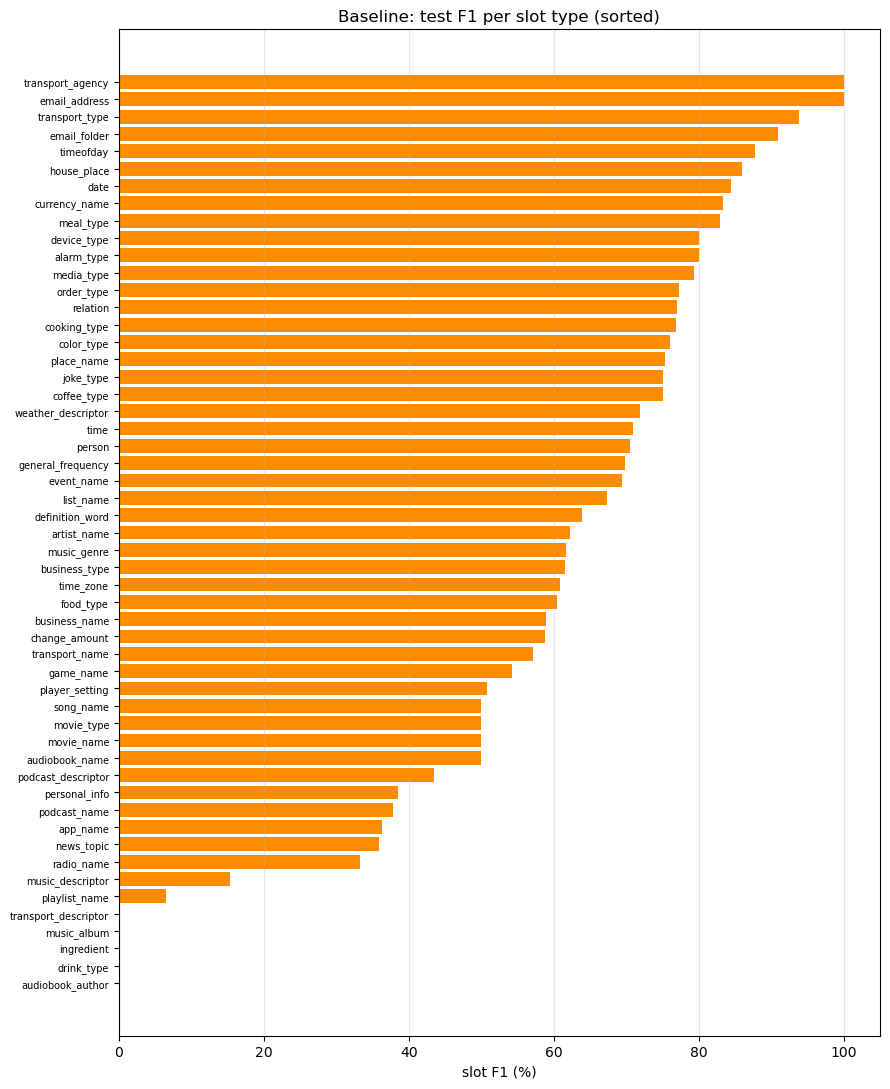

weakest slot types (type, F1, #gold in test):
  audiobook_author        0.00  n=5
  drink_type              0.00  n=1
  ingredient              0.00  n=6
  music_album             0.00  n=1
  transport_descriptor    0.00  n=2
  playlist_name           6.45  n=16
  music_descriptor       15.38  n=7
  radio_name             33.33  n=33
  news_topic             35.96  n=49
  app_name               36.36  n=5


In [23]:
def per_type_scores(goldAll, predAll):
    truePos, falsePos, falseNeg = Counter(), Counter(), Counter()

    for goldSlots, predSlots in zip(goldAll, predAll):
        goldCounts, predCounts = Counter(goldSlots), Counter(predSlots)
        matched = goldCounts & predCounts

        for (slotType, _), count in matched.items():
            truePos[slotType] += count
        for (slotType, _), count in (predCounts - matched).items():
            falsePos[slotType] += count
        for (slotType, _), count in (goldCounts - matched).items():
            falseNeg[slotType] += count

    rows = []
    for slotType in sorted(set(truePos) | set(falsePos) | set(falseNeg)):
        denominator = 2 * truePos[slotType] + falsePos[slotType] + falseNeg[slotType]
        f1 = 100 * 2 * truePos[slotType] / denominator if denominator else 0.0
        numGold = truePos[slotType] + falseNeg[slotType]
        rows.append((slotType, f1, numGold))
    return rows


testGoldSlots = [example["gold_slots"] for example in encoded["test"]]
slotRows = per_type_scores(testGoldSlots, baseTestOut["pred_slots"])
slotRows.sort(key=lambda row: row[1])

plt.figure(figsize=(9, 11))
plt.barh([row[0] for row in slotRows], [row[1] for row in slotRows], color="darkorange")
plt.xlabel("slot F1 (%)")
plt.title("Baseline: test F1 per slot type (sorted)")
plt.yticks(fontsize=7)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("weakest slot types (type, F1, #gold in test):")
for slotType, f1, numGold in slotRows[:10]:
    print(f"  {slotType:<22}{f1:6.2f}  n={numGold}")

In [24]:
# concrete error cases (random sample, fixed seed)
rng = random.Random(SEED)
test_records = splits["test"]

intent_err = [i for i, (g_, p_) in enumerate(zip(testGoldIntents, testPredIntents)) if g_ != p_]
slot_err = [i for i in range(len(test_records))
            if Counter(testGoldSlots[i]) != Counter(baseTestOut["pred_slots"][i])
            ]

print(f"test intent errors: {len(intent_err)}/{len(test_records)} | test utterances with >=1 slot error: {len(slot_err)}/{len(test_records)}\n")

print("intent errors")
for i in rng.sample(intent_err, min(6, len(intent_err))):
    print(f"utt: {test_records[i]['utt']}\n  gold: {testGoldIntents[i]} | pred: {testPredIntents[i]}")

print("\nslot errors")
for i in rng.sample(slot_err, min(6, len(slot_err))):
    print(f"utt: {test_records[i]['utt']}\n  gold: {testGoldSlots[i]}\n  pred: {baseTestOut['pred_slots'][i]}")

test intent errors: 455/2974 | test utterances with >=1 slot error: 914/2974

intent errors
utt: please summarize the latest george r. r. martin ice and fire book
  gold: qa_factoid | pred: play_audiobook
utt: hey what has been happening interesting in sports lately
  gold: general_quirky | pred: news_query
utt: what is a neutral density filter and would i want a gradient one or a solid one also which would be better in style between the screw on one and the square ones
  gold: qa_factoid | pred: recommendation_locations
utt: start chapter five of physics for future presidents
  gold: play_audiobook | pred: qa_factoid
utt: boiling
  gold: cooking_recipe | pred: qa_factoid
utt: can you let delta know i'm never using them again
  gold: social_post | pred: calendar_set

slot errors
utt: is it going to rain at one p. m. today
  gold: [('weather_descriptor', 'going to rain'), ('time', 'one p. m.'), ('date', 'today')]
  pred: [('weather_descriptor', 'rain'), ('time', 'one p. m.'), ('date', '

---
# BiLSTM + attention

Identical to the baseline (same GloVe embeddings, 2-layer BiLSTM, dropout, word-dropout, optimizer, scheduler, checkpoint rule), except:

| Part | Change |
|---|---|
| Attention | additive attention over the top-layer BiLSTM outputs: e_t = vᵀ tanh(W h_t), α = softmax(e) with padding masked to −∞, context c = Σ α_t h_t |
| Task 1 (intent) | linear layer on the attention context c (256-d) instead of the final hidden states |
| Task 2 (slots) | linear layer on [h_t ; c] (512-d), so every token's tag decision also sees a sentence-level summary |

### Model: joint BiLSTM with attention

In [25]:
ATTN_DIM = 128
ATTN_CKPT = os.path.join(SAVE_DIR, "bilstm_attention_best.pt")

class BiLSTMAttentionJoint(nn.Module):
    def __init__(self, vocabSize, embDim, hiddenSize, numLayers, numIntents, numTags,
                 dropout, padIdx, attnDim=ATTN_DIM, pretrained=None):
        super().__init__()
        self.padIdx = padIdx
        self.embedding = nn.Embedding(vocabSize, embDim, padding_idx=padIdx)
        if pretrained is not None:
            self.embedding.weight.data.copy_(pretrained)

        self.embDropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(embDim, hiddenSize, num_layers=numLayers, batch_first=True,
                            bidirectional=True, dropout=dropout if numLayers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)

        encDim = 2 * hiddenSize
        self.attnProj = nn.Linear(encDim, attnDim)
        self.attnScore = nn.Linear(attnDim, 1, bias=False)

        self.intentHead = nn.Linear(encDim, numIntents)
        self.slotHead = nn.Linear(2 * encDim, numTags)   

        self.lastAttention = None   # kept for visualisation

    def forward(self, ids, lengths):
        mask = ids.ne(self.padIdx)                                   
        embedded = self.embDropout(self.embedding(ids))

        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packedOut, _ = self.lstm(packed)
        seqOut, _ = pad_packed_sequence(packedOut, batch_first=True, total_length=ids.size(1))  

        scores = self.attnScore(torch.tanh(self.attnProj(seqOut))).squeeze(-1)   
        scores = scores.masked_fill(~mask, float("-inf"))                         
        attnWeights = torch.softmax(scores, dim=-1)                               
        context = torch.bmm(attnWeights.unsqueeze(1), seqOut).squeeze(1)         
        self.lastAttention = attnWeights.detach()

        intentLogits = self.intentHead(self.dropout(context))
        contextPerToken = context.unsqueeze(1).expand(-1, seqOut.size(1), -1)     
        slotLogits = self.slotHead(self.dropout(torch.cat([seqOut, contextPerToken], dim=-1)))
        return intentLogits, slotLogits


def build_attention():
    return BiLSTMAttentionJoint(len(wordToId), EMBEDDING_DIM, HIDDEN_SIZE, NUM_LAYERS,
                                len(intentToId), len(tagToId), DROPOUT, PAD_ID,
                                pretrained=embedding_matrix).to(device)

set_seed()
attnModel = build_attention()
print(attnModel)
attnTotal, attnTrainable = count_params(attnModel)
print(f"\ntotal parameters: {attnTotal:,} | trainable: {attnTrainable:,}")
assert attnTotal <= 20_000_000

# sanity check
ids, tags, lengths, intentIds, tokens = next(iter(devLoader))
attnModel.eval()
with torch.no_grad():
    attnModel(ids.to(device), lengths.to(device))
w = attnModel.lastAttention.cpu()
print("row sums:", w.sum(-1)[:3], "| total weight on padding:", w[ids.eq(PAD_ID)].sum().item())

BiLSTMAttentionJoint(
  (embedding): Embedding(5304, 300, padding_idx=0)
  (embDropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(300, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (attnProj): Linear(in_features=256, out_features=128, bias=True)
  (attnScore): Linear(in_features=128, out_features=1, bias=False)
  (intentHead): Linear(in_features=256, out_features=60, bias=True)
  (slotHead): Linear(in_features=512, out_features=221, bias=True)
)

total parameters: 2,588,601 | trainable: 2,588,601
row sums: tensor([1., 1., 1.]) | total weight on padding: 0.0


### Train the attention model (training split)

Same seed, optimizer, scheduler, early-stopping patience and checkpoint rule as the baseline.

In [26]:
set_seed()
attnModel = build_attention()
attnHistory, attnBest, attnTime = train_model(attnModel, ATTN_CKPT, tag="BiLSTM + attention")

[BiLSTM + attention] epoch   1 | train loss 3.0655 | val loss 1.4427 | val intent acc  76.24 | val slot F1  56.29 | score  66.27 | lr 0.01000 | 6.1s  <- saved
[BiLSTM + attention] epoch   2 | train loss 1.5478 | val loss 1.1443 | val intent acc  80.82 | val slot F1  64.33 | score  72.57 | lr 0.01000 | 6.4s  <- saved
[BiLSTM + attention] epoch   3 | train loss 1.2257 | val loss 1.0693 | val intent acc  82.19 | val slot F1  68.64 | score  75.41 | lr 0.01000 | 6.0s  <- saved
[BiLSTM + attention] epoch   4 | train loss 1.0904 | val loss 1.0593 | val intent acc  83.18 | val slot F1  67.73 | score  75.46 | lr 0.01000 | 6.1s  <- saved
[BiLSTM + attention] epoch   5 | train loss 1.0227 | val loss 1.0801 | val intent acc  83.52 | val slot F1  67.83 | score  75.67 | lr 0.01000 | 6.1s  <- saved
[BiLSTM + attention] epoch   6 | train loss 0.9718 | val loss 1.0473 | val intent acc  84.80 | val slot F1  69.63 | score  77.22 | lr 0.01000 | 6.5s  <- saved
[BiLSTM + attention] epoch   7 | train loss 0.

### Learning curves (attention model)

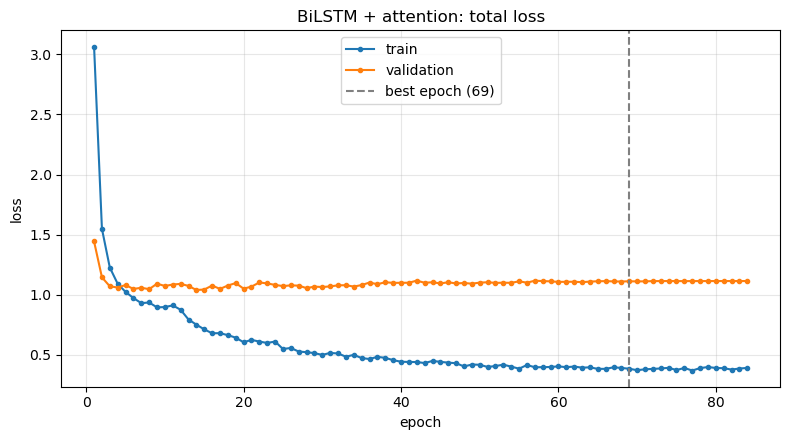

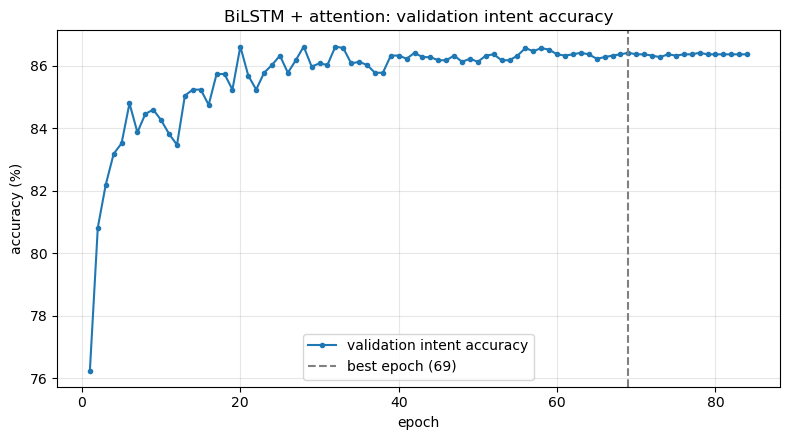

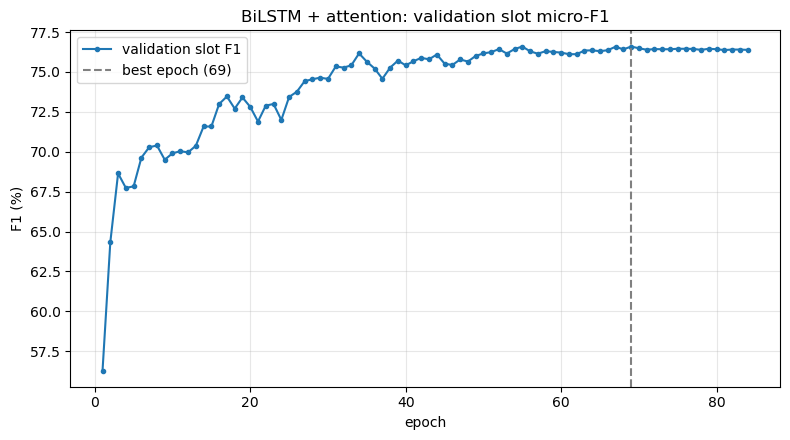

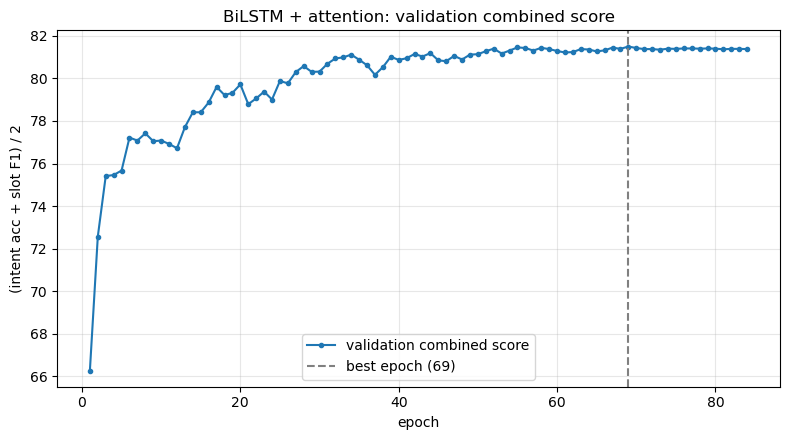

In [27]:
plot_curve(attnHistory, [("train_loss", "train"), ("val_loss", "validation")],
           "BiLSTM + attention: total loss", "loss", attnBest["epoch"])
plot_curve(attnHistory, [("val_intent_acc", "validation intent accuracy")],
           "BiLSTM + attention: validation intent accuracy", "accuracy (%)", attnBest["epoch"])
plot_curve(attnHistory, [("val_slot_f1", "validation slot F1")],
           "BiLSTM + attention: validation slot micro-F1", "F1 (%)", attnBest["epoch"])
plot_curve(attnHistory, [("val_score", "validation combined score")],
           "BiLSTM + attention: validation combined score", "(intent acc + slot F1) / 2", attnBest["epoch"])

### Final evaluation of the attention checkpoint

In [28]:
attnModel, attnValOut, attnTestOut, attnResults = final_evaluation(
    ATTN_CKPT, attnHistory, attnBest, attnTime, "Stage-1 BiLSTM + attention", buildFn=build_attention)

with open(os.path.join(SAVE_DIR, "attention_results.json"), "w") as f:
    json.dump(attnResults, f, indent=2)
with open(os.path.join(SAVE_DIR, "attention_history.json"), "w") as f:
    json.dump(attnHistory, f, indent=2)

loaded ../Results/bilstm_attention_best.pt (saved at epoch 69)
validation scores reproduce the best training-time score

Stage-1 BiLSTM + attention | total params 2,588,601 | trainable 2,588,601 | best epoch 69 | epochs run 84
  VALIDATION  intent accuracy: 86.42% | slot micro-F1: 76.59%
  TEST        intent accuracy: 85.57% | slot micro-F1: 73.13%


### Comparison: baseline vs. attention

In [29]:
print(f"{'Model version':<26}{'Split':<12}{'#params':>12}{'#trainable':>12}{'Intent acc':>12}{'Slot F1':>10}{'Epochs':>8}")
for res, name in ((baselineResults, "BiLSTM baseline"), (attnResults, "BiLSTM + attention")):
    for split in ("validation", "test"):
        m = res[split]
        print(f"{name:<26}{split.capitalize():<12}{res['total_params']:>12,}{res['trainable_params']:>12,}"
              f"{m['intent_acc']:>12.2f}{m['slot_f1']:>10.2f}{res['epochs_run']:>8}")

Model version             Split            #params  #trainable  Intent acc   Slot F1  Epochs
BiLSTM baseline           Validation     2,499,001   2,499,001       85.24     74.14      77
BiLSTM baseline           Test           2,499,001   2,499,001       84.70     71.21      77
BiLSTM + attention        Validation     2,588,601   2,588,601       86.42     76.59      84
BiLSTM + attention        Test           2,588,601   2,588,601       85.57     73.13      84


### Attention model: error analysis on the validation split

Used to diagnose weaknesses for Stage 2. The test split is not used for this, so Stage 2 design choices are not guided by test errors.

In [30]:
devGoldIntents = [idToIntent[e["intent"]] for e in encoded["dev"]]
devGoldSlots = [e["gold_slots"] for e in encoded["dev"]]
devPredIntents = attnValOut["pred_intents"]
devPredSlots = attnValOut["pred_slots"]

pairCounts = Counter((g, p) for g, p in zip(devGoldIntents, devPredIntents) if g != p)
print(f"dev intent errors: {sum(pairCounts.values())} / {len(devGoldIntents)}")
print("most confused intent pairs (count, true -> predicted):")
for (g, p), n in pairCounts.most_common(12):
    print(f"  {n:3d}  {g}  ->  {p}")

devSlotRows = per_type_scores(devGoldSlots, devPredSlots)
devSlotRows.sort(key=lambda row: row[1])
print("\nweakest slot types on dev (type, F1, #gold):")
for slotType, f1, numGold in devSlotRows[:12]:
    print(f"  {slotType:<22}{f1:6.2f}  n={numGold}")

rng = random.Random(SEED)
devSlotErr = [i for i in range(len(devGoldSlots)) if Counter(devGoldSlots[i]) != Counter(devPredSlots[i])]
print(f"\ndev utterances with >=1 slot error: {len(devSlotErr)} / {len(devGoldSlots)}\n")
for i in rng.sample(devSlotErr, 8):
    print(f"utt: {splits['dev'][i]['utt']}\n  gold: {devGoldSlots[i]}\n  pred: {devPredSlots[i]}")

dev intent errors: 276 / 2033
most confused intent pairs (count, true -> predicted):
    7  qa_factoid  ->  general_quirky
    6  general_quirky  ->  news_query
    5  general_quirky  ->  datetime_query
    5  general_quirky  ->  qa_definition
    5  general_quirky  ->  qa_factoid
    4  qa_factoid  ->  qa_definition
    4  calendar_query  ->  calendar_set
    4  calendar_set  ->  weather_query
    4  calendar_set  ->  calendar_query
    4  recommendation_events  ->  news_query
    3  weather_query  ->  general_quirky
    3  play_music  ->  play_radio

weakest slot types on dev (type, F1, #gold):
  game_type               0.00  n=1
  music_descriptor        0.00  n=8
  sport_type              0.00  n=1
  transport_descriptor    0.00  n=0
  podcast_name           21.05  n=8
  ingredient             28.57  n=4
  song_name              29.27  n=23
  alarm_type             33.33  n=2
  cooking_type           33.33  n=2
  audiobook_name         34.29  n=16
  playlist_name          42.11  n=

### Attention visualisation

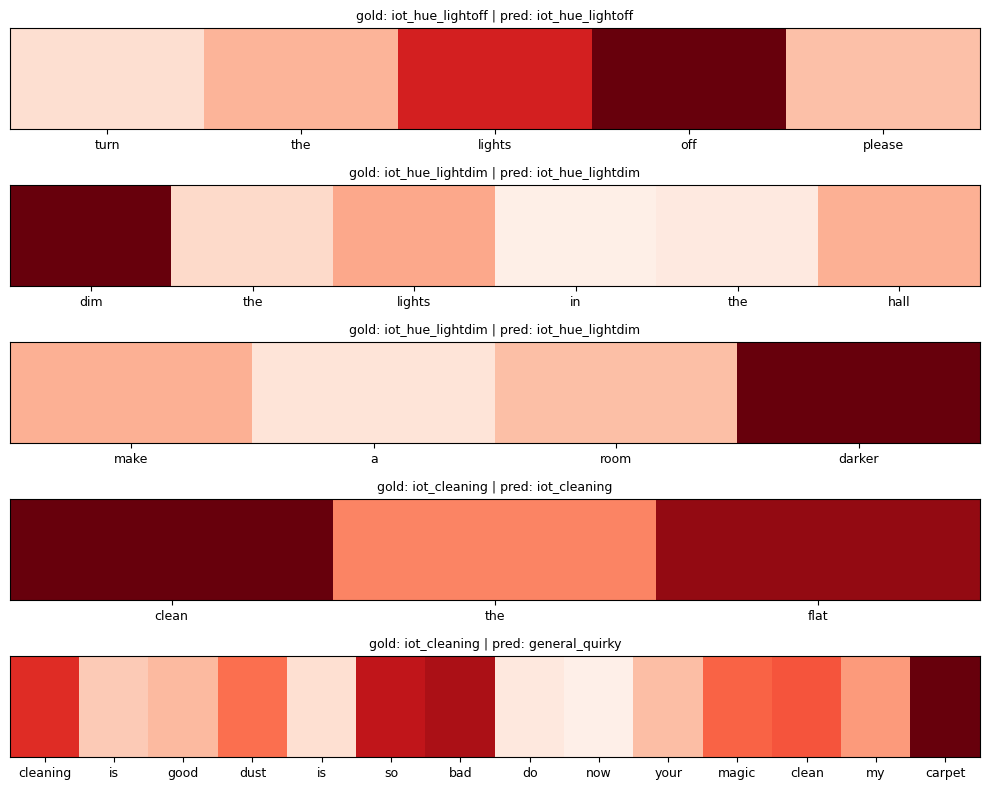

In [31]:
def show_attention(model, records, n=5):
    examples, _ = encode_split(records[:n])
    ids, tags, lengths, intentIds, tokens = collate_fn(examples)
    model.eval()
    with torch.no_grad():
        intentLogits, _ = model(ids.to(device), lengths.to(device))
    weights = model.lastAttention.cpu()

    fig, axes = plt.subplots(n, 1, figsize=(10, 1.6 * n))
    for k in range(n):
        L = len(tokens[k])
        axes[k].imshow(weights[k, :L].unsqueeze(0).numpy(), cmap="Reds", aspect="auto", vmin=0)
        axes[k].set_xticks(range(L))
        axes[k].set_xticklabels(tokens[k], fontsize=9)
        axes[k].set_yticks([])
        pred = idToIntent[intentLogits[k].argmax().item()]
        axes[k].set_title(f"gold: {records[k]['intent']} | pred: {pred}", fontsize=9)
    plt.tight_layout()
    plt.show()

show_attention(attnModel, splits["dev"], n=5)

---
*Stage 2 (AI-enhanced system) goes below this line. `train_model`, `predict`, `score_split` and `final_evaluation` take the model/checkpoint as arguments so they can be reused with the same scoring rules.*

# Stage 2


## Experiment 1: lower starting learning rate

**Motivation.** In both Stage-1 runs the validation loss bottoms out around epochs 3–14 and then flattens or rises while training loss keeps falling, and almost all later gains coincide with `ReduceLROnPlateau` halving the LR (0.01 → ~3e-4). The best checkpoints (epochs 62 / 69) are reached only once the LR is already small, which suggests the starting LR of 0.01 is too high for Adam on this model.

**Change.** Identical to the Stage-1 BiLSTM + attention model (same architecture, GloVe init, dropout, word-dropout, seed, optimizer, scheduler, early-stopping patience and checkpoint rule) — **only the starting learning rate changes from 0.01 to 0.001**.

**Evaluation.** Validation split only. The test split is held out and is evaluated once, at the very end, on the final chosen system. Results are saved to a new checkpoint so the Stage-1 checkpoint is not overwritten.

In [32]:
# Stage 2 / Exp 1 config — everything else is inherited unchanged from Stage 1
EXP1_LR = 1e-3
EXP1_TAG = "Attn lr=1e-3"
EXP1_CKPT = os.path.join(SAVE_DIR, "stage2_attn_lr1e-3_best.pt")
assert EXP1_CKPT not in (BASELINE_CKPT, ATTN_CKPT), "must not overwrite a Stage-1 checkpoint"

set_seed()
exp1Model = build_attention()
exp1History, exp1Best, exp1Time = train_model(exp1Model, EXP1_CKPT, lr=EXP1_LR, tag=EXP1_TAG)

[Attn lr=1e-3] epoch   1 | train loss 4.7529 | val loss 2.9934 | val intent acc  46.68 | val slot F1   7.01 | score  26.84 | lr 0.00100 | 10.4s  <- saved
[Attn lr=1e-3] epoch   2 | train loss 2.4974 | val loss 1.6864 | val intent acc  73.44 | val slot F1  34.70 | score  54.07 | lr 0.00100 | 10.4s  <- saved
[Attn lr=1e-3] epoch   3 | train loss 1.7394 | val loss 1.3055 | val intent acc  79.29 | val slot F1  46.54 | score  62.92 | lr 0.00100 | 10.5s  <- saved
[Attn lr=1e-3] epoch   4 | train loss 1.3915 | val loss 1.1590 | val intent acc  82.34 | val slot F1  55.13 | score  68.73 | lr 0.00100 | 10.2s  <- saved
[Attn lr=1e-3] epoch   5 | train loss 1.1830 | val loss 1.0501 | val intent acc  83.62 | val slot F1  58.37 | score  71.00 | lr 0.00100 | 10.2s  <- saved
[Attn lr=1e-3] epoch   6 | train loss 1.0404 | val loss 0.9933 | val intent acc  84.55 | val slot F1  63.49 | score  74.02 | lr 0.00100 | 10.2s  <- saved
[Attn lr=1e-3] epoch   7 | train loss 0.9314 | val loss 0.9583 | val intent 

### Validation-only evaluation of the Exp 1 checkpoint

`dev_evaluation` is the Stage-2 counterpart of `final_evaluation`: it reloads the best checkpoint into a freshly built model and scores **only the validation split**, so test is never touched during development.

In [33]:
def dev_evaluation(ckptPath, best, buildFn):
    """Reload a checkpoint into a fresh model and score the validation split only (test stays held out)."""
    model = buildFn()
    checkpoint = torch.load(ckptPath, map_location=device)
    model.load_state_dict(checkpoint["model_state"])

    devOut = predict(model, devLoader)
    devMetrics = score_split(devOut, encoded["dev"])

    # must reproduce the best validation score recorded during training
    assert abs(devMetrics["combined"] - best["score"]) < 0.01, (devMetrics, best)
    return model, devOut, devMetrics, checkpoint["epoch"]


exp1Model, exp1DevOut, exp1DevMetrics, exp1BestEpoch = dev_evaluation(EXP1_CKPT, exp1Best, build_attention)
exp1Total, exp1Trainable = count_params(exp1Model)

exp1Results = {
    "label": "Stage-2 Exp1: BiLSTM + attention, lr=1e-3",
    "start_lr": EXP1_LR,
    "total_params": exp1Total,
    "trainable_params": exp1Trainable,
    "best_epoch": exp1BestEpoch,
    "epochs_run": len(exp1History),
    "train_time_s": exp1Time,
    "validation": {key: exp1DevMetrics[key] for key in ("intent_acc", "slot_f1", "combined")},
}
with open(os.path.join(SAVE_DIR, "stage2_attn_lr1e-3_results.json"), "w") as f:
    json.dump(exp1Results, f, indent=2)
with open(os.path.join(SAVE_DIR, "stage2_attn_lr1e-3_history.json"), "w") as f:
    json.dump(exp1History, f, indent=2)

# Stage-1 attention numbers are read from the saved JSON files so this cell also works after a kernel restart
with open(os.path.join(SAVE_DIR, "attention_results.json")) as f:
    stage1AttnResults = json.load(f)
with open(os.path.join(SAVE_DIR, "attention_history.json")) as f:
    stage1AttnHistory = json.load(f)

def row(name, lr, res):
    v = res["validation"]
    combined = v.get("combined", round((v["intent_acc"] + v["slot_f1"]) / 2, 2))
    print(f"{name:<30}{lr:>9g}{res['best_epoch']:>7}{res['epochs_run']:>8}{res['train_time_s']:>9.0f}"
          f"{v['intent_acc']:>12.2f}{v['slot_f1']:>10.2f}{combined:>10.2f}")

print(f"{'Run (validation split)':<30}{'start lr':>9}{'best':>7}{'epochs':>8}{'time(s)':>9}"
      f"{'Intent acc':>12}{'Slot F1':>10}{'Combined':>10}")
row("Stage-1 attention", LEARNING_RATE, stage1AttnResults)
row("Stage-2 Exp1 attention", EXP1_LR, exp1Results)

Run (validation split)         start lr   best  epochs  time(s)  Intent acc   Slot F1  Combined
Stage-1 attention                  0.01     69      84      624       86.42     76.59     81.50
Stage-2 Exp1 attention            0.001     45      60      617       86.67     77.97     82.32


### Learning curves: Stage-1 (lr = 0.01) vs Exp 1 (lr = 0.001)

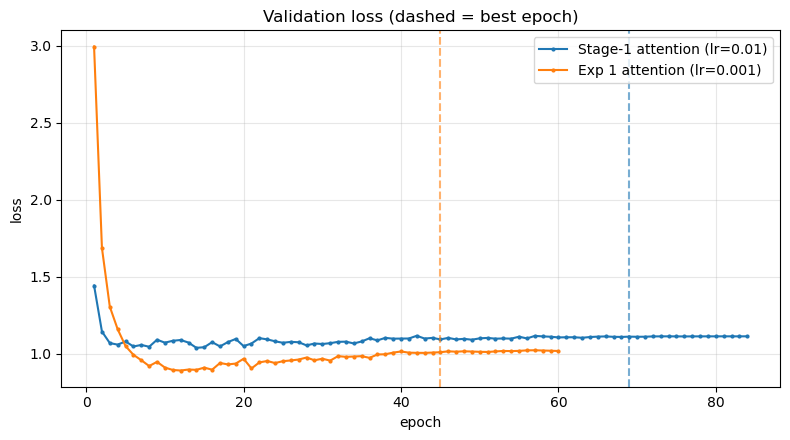

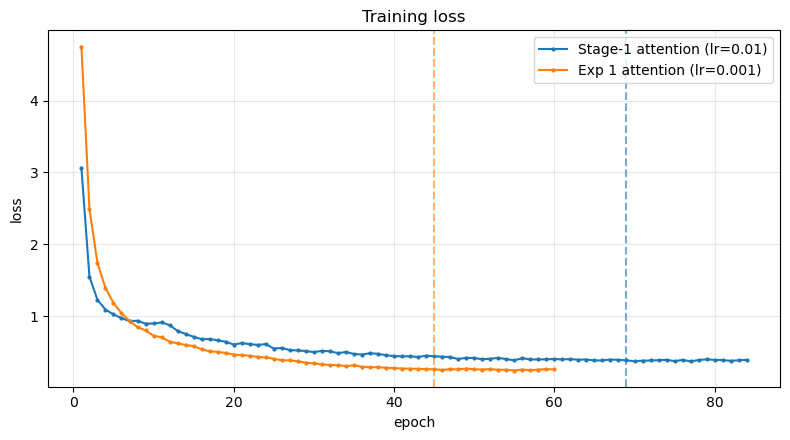

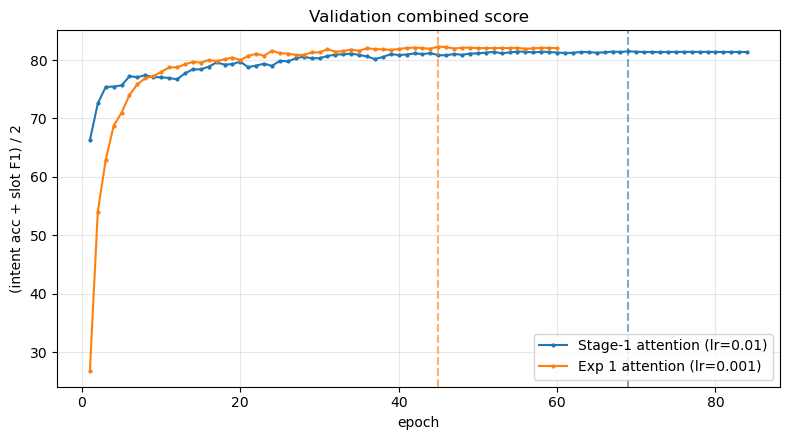

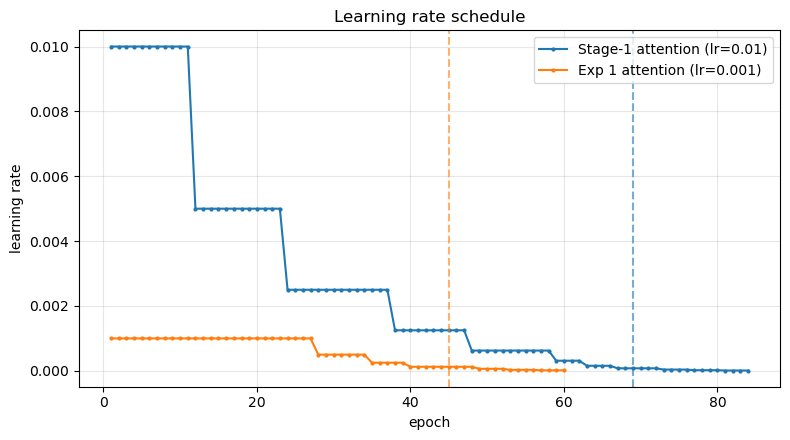

In [34]:
def plot_compare(runs, key, title, ylabel):
    """Overlay one history metric for several runs. `runs` is a list of (history, label, bestEpoch)."""
    plt.figure(figsize=(8, 4.5))
    for history, label, bestEpoch in runs:
        line, = plt.plot(get_history_values(history, "epoch"), get_history_values(history, key),
                         label=label, marker="o", markersize=2)
        plt.axvline(bestEpoch, color=line.get_color(), linestyle="--", alpha=0.6)
    plt.title(title)
    plt.xlabel("epoch")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

exp1Runs = [
    (stage1AttnHistory, "Stage-1 attention (lr=0.01)", stage1AttnResults["best_epoch"]),
    (exp1History, "Exp 1 attention (lr=0.001)", exp1BestEpoch),
]
plot_compare(exp1Runs, "val_loss", "Validation loss (dashed = best epoch)", "loss")
plot_compare(exp1Runs, "train_loss", "Training loss", "loss")
plot_compare(exp1Runs, "val_score", "Validation combined score", "(intent acc + slot F1) / 2")
plot_compare(exp1Runs, "lr", "Learning rate schedule", "learning rate")

## Experiment 2: regularisation (2a: intent label smoothing, 2b: lower embedding learning rate)

**Motivation (from Exp 1).** Splitting the validation loss by task shows the overfitting is mostly in the intent head: val intent loss is lowest at epoch 8 (0.541) and rises 24% by the end, while val slot loss rises only 10%. Intent accuracy stays flat over the same epochs, so the model is becoming over-confident rather than less accurate. Separately, the fine-tuned embedding table holds 5,304 × 300 ≈ 1.59M of the 2.59M parameters (61%), trained on only 11.5k short utterances.

Both experiments start from **Exp 1** (lr = 1e-3, same model, seed, scheduler, patience and checkpoint rule) and change exactly one thing:

| Run | Change vs Exp 1 |
|---|---|
| Exp 2a | label smoothing ε = 0.1 on the intent cross-entropy, **training loss only** |
| Exp 2b | embedding learning rate = 0.1 × base lr (1e-4); all other parameters keep 1e-3 |

**Keeping the numbers comparable.**
* Validation loss is still computed by the unchanged Stage-1 `predict` / `compute_losses`, i.e. **unsmoothed**, so val loss is directly comparable with Exp 1.
* For 2a the logged `train_intent_loss` is also the **unsmoothed** CE (computed on the same forward pass); the smoothed loss that is actually back-propagated is logged separately as `train_intent_loss_smoothed`.
* Validation split only; test stays held out. New checkpoints, Stage-1 and Exp-1 files are not overwritten.

### Stage-2 training loop

`train_model_s2` is the same loop as Stage-1 `train_model` (same scheduler, early stopping, checkpoint rule and log line) with two extra arguments: `intentSmoothing` (applied to the training loss only) and `embLrScale` (embedding learning rate as a fraction of `lr`; `0` freezes the embeddings). With the defaults (`0.0`, `1.0`) it reproduces `train_model`.

In [35]:
# helpers re-defined from earlier cells (identical) so the Exp 2 cells run after a kernel restart
def get_history_values(history, key):
    return [record[key] for record in history]

def plot_compare(runs, key, title, ylabel):
    """Overlay one history metric for several runs. `runs` is a list of (history, label, bestEpoch)."""
    plt.figure(figsize=(8, 4.5))
    for history, label, bestEpoch in runs:
        line, = plt.plot(get_history_values(history, "epoch"), get_history_values(history, key),
                         label=label, marker="o", markersize=2)
        plt.axvline(bestEpoch, color=line.get_color(), linestyle="--", alpha=0.6)
    plt.title(title)
    plt.xlabel("epoch")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


def dev_evaluation(ckptPath, best, buildFn):
    """Same as in Exp 1 (re-defined here so Exp 2 runs after a kernel restart without re-running Exp 1).
    Reload a checkpoint into a fresh model and score the validation split only (test stays held out)."""
    model = buildFn()
    checkpoint = torch.load(ckptPath, map_location=device)
    model.load_state_dict(checkpoint["model_state"])
    devOut = predict(model, devLoader)
    devMetrics = score_split(devOut, encoded["dev"])
    assert abs(devMetrics["combined"] - best["score"]) < 0.01, (devMetrics, best)
    return model, devOut, devMetrics, checkpoint["epoch"]


def make_optimizer(model, lr, embLrScale=1.0):
    """Adam with the embedding table in its own parameter group (lr * embLrScale; 0 = frozen).
    The non-embedding group is first, so param_groups[0]['lr'] is the base lr that gets logged."""
    embParams = list(model.embedding.parameters())
    embIds = {id(p) for p in embParams}
    otherParams = [p for p in model.parameters() if id(p) not in embIds]

    groups = [{"params": otherParams, "lr": lr}]
    if embLrScale > 0:
        groups.append({"params": embParams, "lr": lr * embLrScale})
    else:
        for p in embParams:
            p.requires_grad_(False)
    return torch.optim.Adam(groups, lr=lr)


def train_one_epoch_s2(model, optimizer, intentSmoothing=0.0):
    """Same as train_one_epoch, but the back-propagated intent loss can be label-smoothed.
    Logged losses are always the UNSMOOTHED ones so they stay comparable across runs."""
    model.train()
    lossTotals = {"loss": 0.0, "intent_loss": 0.0, "slot_loss": 0.0, "intent_loss_smoothed": 0.0}

    for ids, tags, lengths, intentIds, _ in trainLoader:
        ids, tags, lengths, intentIds = move_batch_to_device(ids, tags, lengths, intentIds)
        if WORD_DROPOUT > 0:
            ids = apply_word_dropout(ids)

        optimizer.zero_grad()
        intentLogits, slotLogits = model(ids, lengths)
        loss, intentLoss, slotLoss = compute_losses(intentLogits, slotLogits, intentIds, tags)  # unsmoothed

        if intentSmoothing > 0:
            intentLossSmoothed = F.cross_entropy(intentLogits, intentIds, label_smoothing=intentSmoothing)
        else:
            intentLossSmoothed = intentLoss
        (intentLossSmoothed + slotLoss).backward()
        clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        lossTotals["loss"] += loss.item()
        lossTotals["intent_loss"] += intentLoss.item()
        lossTotals["slot_loss"] += slotLoss.item()
        lossTotals["intent_loss_smoothed"] += intentLossSmoothed.item()

    numBatches = len(trainLoader)
    return {key: total / numBatches for key, total in lossTotals.items()}


def train_model_s2(model, ckptPath, lr, intentSmoothing=0.0, embLrScale=1.0,
                   numEpochs=NUM_EPOCHS, patience=PATIENCE, tag="model"):
    """Stage-1 train_model + intentSmoothing (train loss only) + embLrScale. Same selection rule."""
    optimizer = make_optimizer(model, lr, embLrScale)
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

    history = []
    best = {"score": -1.0, "epoch": 0}
    badEpochs = 0
    startTime = time.time()

    for epoch in range(1, numEpochs + 1):
        epochStart = time.time()
        trainLosses = train_one_epoch_s2(model, optimizer, intentSmoothing)

        valOut = predict(model, devLoader)            # unchanged: unsmoothed val losses
        valMetrics = score_split(valOut, encoded["dev"])
        scheduler.step(valMetrics["combined"])

        record = {
            "epoch": epoch,
            "train_loss": trainLosses["loss"],
            "train_intent_loss": trainLosses["intent_loss"],
            "train_intent_loss_smoothed": trainLosses["intent_loss_smoothed"],
            "train_slot_loss": trainLosses["slot_loss"],
            "val_loss": valOut["loss"],
            "val_intent_loss": valOut["intent_loss"],
            "val_slot_loss": valOut["slot_loss"],
            "val_intent_acc": valMetrics["intent_acc"],
            "val_slot_f1": valMetrics["slot_f1"],
            "val_score": valMetrics["combined"],
            "lr": optimizer.param_groups[0]["lr"],
            "epoch_time": time.time() - epochStart,
            "elapsed": time.time() - startTime,
        }
        history.append(record)

        improved = valMetrics["combined"] > best["score"]
        if improved:
            best = {"score": valMetrics["combined"], "epoch": epoch, "metrics": valMetrics}
            badEpochs = 0
            torch.save({"model_state": model.state_dict(), "epoch": epoch,
                        "val_score": valMetrics["combined"], "val_metrics": valMetrics}, ckptPath)
        else:
            badEpochs += 1

        savedMarker = "  <- saved" if improved else ""
        print(f"[{tag}] epoch {epoch:3d} | train loss {record['train_loss']:.4f} | val loss {record['val_loss']:.4f} "
              f"(intent {record['val_intent_loss']:.3f}, slot {record['val_slot_loss']:.3f}) | "
              f"val intent acc {valMetrics['intent_acc']:6.2f} | val slot F1 {valMetrics['slot_f1']:6.2f} | "
              f"score {valMetrics['combined']:6.2f} | lr {record['lr']:.5f} | {record['epoch_time']:.1f}s{savedMarker}")

        if badEpochs >= patience:
            print(f"early stopping: no improvement for {patience} epochs")
            break

    totalTime = time.time() - startTime
    print(f"\ntraining finished: {len(history)} epochs in {totalTime:.1f}s")
    print(f"best epoch: {best['epoch']} | best validation score: {best['score']:.2f} "
          f"(intent acc {best['metrics']['intent_acc']:.2f}, slot F1 {best['metrics']['slot_f1']:.2f}) | checkpoint: {ckptPath}")
    return history, best, totalTime


def save_s2_results(prefix, label, ckptPath, history, best, trainTime, buildFn, **config):
    """dev-only evaluation of the best checkpoint + save results/history JSON under SAVE_DIR/<prefix>_*.json"""
    model, devOut, devMetrics, bestEpoch = dev_evaluation(ckptPath, best, buildFn)
    total, trainable = count_params(model)
    results = {
        "label": label, **config,
        "total_params": total, "trainable_params": trainable,
        "best_epoch": bestEpoch, "epochs_run": len(history), "train_time_s": trainTime,
        "validation": {key: devMetrics[key] for key in ("intent_acc", "slot_f1", "combined")},
    }
    with open(os.path.join(SAVE_DIR, f"{prefix}_results.json"), "w") as f:
        json.dump(results, f, indent=2)
    with open(os.path.join(SAVE_DIR, f"{prefix}_history.json"), "w") as f:
        json.dump(history, f, indent=2)
    return model, devOut, results

EXP1_LR = 1e-3   # re-stated so the Exp 2 cells also run after a kernel restart without re-training Exp 1

### Exp 2a: label smoothing (ε = 0.1) on the intent training loss

In [36]:
EXP2A_SMOOTHING = 0.1
EXP2A_TAG = "Exp2a intent LS=0.1"
EXP2A_PREFIX = "stage2_exp2a_intent_ls0.1"
EXP2A_CKPT = os.path.join(SAVE_DIR, f"{EXP2A_PREFIX}_best.pt")
assert EXP2A_CKPT not in (BASELINE_CKPT, ATTN_CKPT, os.path.join(SAVE_DIR, "stage2_attn_lr1e-3_best.pt"))

set_seed()
exp2aModel = build_attention()
exp2aHistory, exp2aBest, exp2aTime = train_model_s2(
    exp2aModel, EXP2A_CKPT, lr=EXP1_LR, intentSmoothing=EXP2A_SMOOTHING, tag=EXP2A_TAG)

exp2aModel, exp2aDevOut, exp2aResults = save_s2_results(
    EXP2A_PREFIX, "Stage-2 Exp2a: attention, lr=1e-3, intent label smoothing 0.1 (train only)",
    EXP2A_CKPT, exp2aHistory, exp2aBest, exp2aTime, build_attention,
    start_lr=EXP1_LR, intent_label_smoothing=EXP2A_SMOOTHING, emb_lr_scale=1.0)

[Exp2a intent LS=0.1] epoch   1 | train loss 4.7681 | val loss 3.0807 (intent 2.130, slot 0.950) | val intent acc  46.14 | val slot F1   9.94 | score  28.04 | lr 0.00100 | 10.7s  <- saved
[Exp2a intent LS=0.1] epoch   2 | train loss 2.5530 | val loss 1.7148 (intent 1.037, slot 0.678) | val intent acc  74.77 | val slot F1  37.13 | score  55.95 | lr 0.00100 | 10.8s  <- saved
[Exp2a intent LS=0.1] epoch   3 | train loss 1.7794 | val loss 1.3574 (intent 0.810, slot 0.547) | val intent acc  79.73 | val slot F1  49.76 | score  64.75 | lr 0.00100 | 10.8s  <- saved
[Exp2a intent LS=0.1] epoch   4 | train loss 1.4257 | val loss 1.1807 (intent 0.709, slot 0.471) | val intent acc  82.64 | val slot F1  60.43 | score  71.53 | lr 0.00100 | 10.8s  <- saved
[Exp2a intent LS=0.1] epoch   5 | train loss 1.2481 | val loss 1.0603 (intent 0.644, slot 0.416) | val intent acc  83.47 | val slot F1  63.49 | score  73.48 | lr 0.00100 | 10.9s  <- saved
[Exp2a intent LS=0.1] epoch   6 | train loss 1.1050 | val lo

### Exp 2b: embedding learning rate = 0.1 × base lr

Set `EXP2B_EMB_LR_SCALE = 0.0` to freeze the embeddings entirely instead (then `trainable_params` drops by ≈1.59M). 0.1 is used by default because ~7% of the vocabulary (words without a GloVe vector, plus `<UNK>`) starts from random vectors and would stay random if frozen.

In [37]:
EXP2B_EMB_LR_SCALE = 0.1
EXP2B_TAG = f"Exp2b emb lr x{EXP2B_EMB_LR_SCALE}"
EXP2B_PREFIX = f"stage2_exp2b_emb_lr_x{EXP2B_EMB_LR_SCALE}"
EXP2B_CKPT = os.path.join(SAVE_DIR, f"{EXP2B_PREFIX}_best.pt")
assert EXP2B_CKPT not in (BASELINE_CKPT, ATTN_CKPT, EXP2A_CKPT, os.path.join(SAVE_DIR, "stage2_attn_lr1e-3_best.pt"))

set_seed()
exp2bModel = build_attention()
exp2bHistory, exp2bBest, exp2bTime = train_model_s2(
    exp2bModel, EXP2B_CKPT, lr=EXP1_LR, embLrScale=EXP2B_EMB_LR_SCALE, tag=EXP2B_TAG)

# a freshly built model has requires_grad=True everywhere, so report trainable params from the trained model
exp2bTrainable = count_params(exp2bModel)[1]
exp2bModel, exp2bDevOut, exp2bResults = save_s2_results(
    EXP2B_PREFIX, f"Stage-2 Exp2b: attention, lr=1e-3, embedding lr x{EXP2B_EMB_LR_SCALE}",
    EXP2B_CKPT, exp2bHistory, exp2bBest, exp2bTime, build_attention,
    start_lr=EXP1_LR, intent_label_smoothing=0.0, emb_lr_scale=EXP2B_EMB_LR_SCALE)
exp2bResults["trainable_params"] = exp2bTrainable
with open(os.path.join(SAVE_DIR, f"{EXP2B_PREFIX}_results.json"), "w") as f:
    json.dump(exp2bResults, f, indent=2)

[Exp2b emb lr x0.1] epoch   1 | train loss 4.8077 | val loss 3.1037 (intent 2.086, slot 1.018) | val intent acc  44.07 | val slot F1   8.65 | score  26.36 | lr 0.00100 | 10.9s  <- saved
[Exp2b emb lr x0.1] epoch   2 | train loss 2.6733 | val loss 1.8446 (intent 1.085, slot 0.759) | val intent acc  71.57 | val slot F1  29.95 | score  50.76 | lr 0.00100 | 10.9s  <- saved
[Exp2b emb lr x0.1] epoch   3 | train loss 1.9453 | val loss 1.4290 (intent 0.797, slot 0.632) | val intent acc  78.31 | val slot F1  42.03 | score  60.17 | lr 0.00100 | 10.9s  <- saved
[Exp2b emb lr x0.1] epoch   4 | train loss 1.6272 | val loss 1.2696 (intent 0.703, slot 0.566) | val intent acc  80.67 | val slot F1  49.75 | score  65.21 | lr 0.00100 | 10.8s  <- saved
[Exp2b emb lr x0.1] epoch   5 | train loss 1.4225 | val loss 1.1455 (intent 0.639, slot 0.507) | val intent acc  82.44 | val slot F1  54.82 | score  68.63 | lr 0.00100 | 11.0s  <- saved
[Exp2b emb lr x0.1] epoch   6 | train loss 1.2717 | val loss 1.0679 (i

### Exp 2 comparison (validation split)

Exp 1 and Stage-1 numbers are read from their saved JSON files. Besides the scores, the table shows where each run's **val intent / slot loss** bottom out and how much they rise afterwards — the overfitting signal Exp 2 is aimed at.

In [38]:
def load_run(prefix):
    with open(os.path.join(SAVE_DIR, f"{prefix}_results.json")) as f:
        res = json.load(f)
    with open(os.path.join(SAVE_DIR, f"{prefix}_history.json")) as f:
        hist = json.load(f)
    return res, hist

def loss_rise(history, key):
    """(epoch of min, min value, % rise from the min to the last epoch)"""
    values = get_history_values(history, key)
    i = int(np.argmin(values))
    return history[i]["epoch"], values[i], 100 * (values[-1] - values[i]) / values[i]

compareRuns = [
    ("Stage-1 attn (lr 0.01)", *load_run("attention")),
    ("Exp1 (lr 1e-3)",         *load_run("stage2_attn_lr1e-3")),
    ("Exp2a (+ intent LS 0.1)", exp2aResults, exp2aHistory),
    (f"Exp2b (+ emb lr x{EXP2B_EMB_LR_SCALE})", exp2bResults, exp2bHistory),
]

print(f"{'Run (validation split)':<26}{'trainable':>11}{'best':>6}{'epochs':>8}{'time(s)':>9}"
      f"{'Intent':>8}{'SlotF1':>8}{'Comb.':>8}   {'val intent loss min@ep / rise':>30}   {'val slot loss min@ep / rise':>28}")
for name, res, hist in compareRuns:
    v = res["validation"]
    combined = v.get("combined", round((v["intent_acc"] + v["slot_f1"]) / 2, 2))
    ie, iv, ir = loss_rise(hist, "val_intent_loss")
    se, sv, sr = loss_rise(hist, "val_slot_loss")
    print(f"{name:<26}{res['trainable_params']:>11,}{res['best_epoch']:>6}{res['epochs_run']:>8}{res['train_time_s']:>9.0f}"
          f"{v['intent_acc']:>8.2f}{v['slot_f1']:>8.2f}{combined:>8.2f}   "
          f"{iv:>14.3f} @ {ie:<3d} / {ir:+5.1f}%   {sv:>12.3f} @ {se:<3d} / {sr:+5.1f}%")

Run (validation split)      trainable  best  epochs  time(s)  Intent  SlotF1   Comb.    val intent loss min@ep / rise    val slot loss min@ep / rise
Stage-1 attn (lr 0.01)      2,588,601    69      84      624   86.42   76.59   81.50            0.648 @ 8   / +17.9%          0.344 @ 35  /  +1.6%
Exp1 (lr 1e-3)              2,588,601    45      60      617   86.67   77.97   82.32            0.549 @ 8   / +23.8%          0.317 @ 16  /  +6.8%
Exp2a (+ intent LS 0.1)     2,588,601    30      45      491   86.87   77.61   82.24            0.559 @ 14  /  +3.8%          0.307 @ 17  /  +3.6%
Exp2b (+ emb lr x0.1)       2,588,601    57      72      786   86.92   77.98   82.45            0.538 @ 17  / +17.2%          0.304 @ 34  /  +2.3%


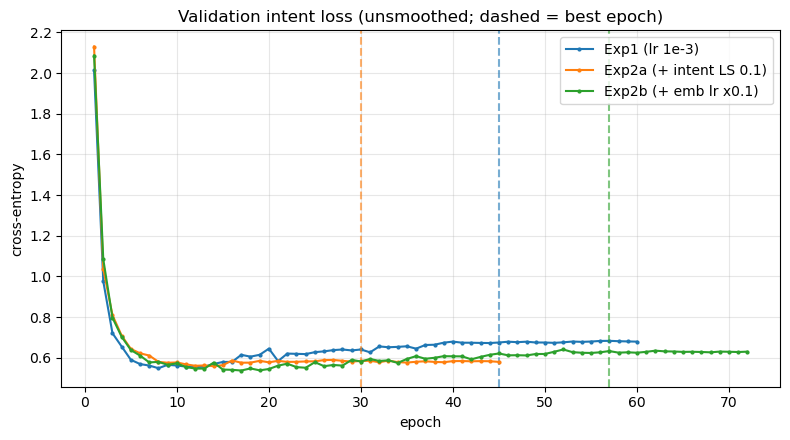

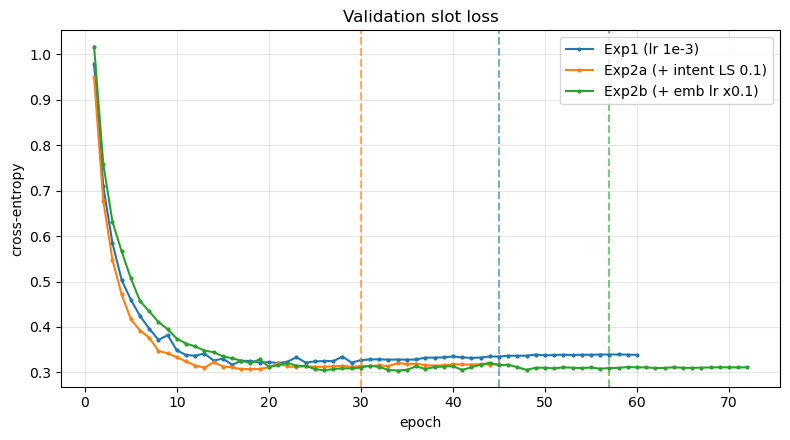

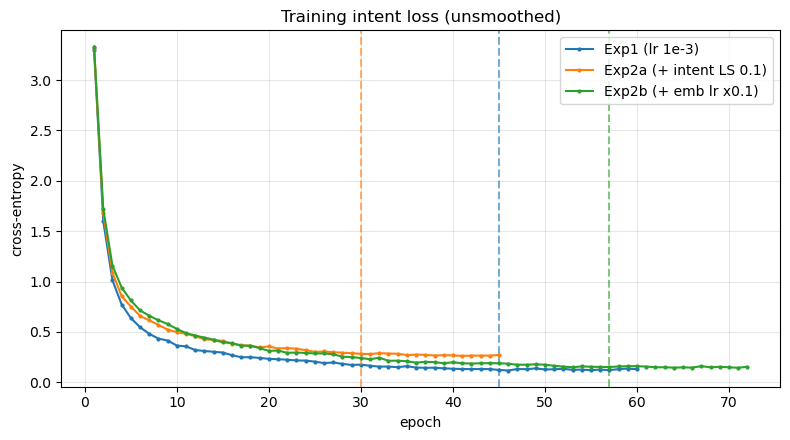

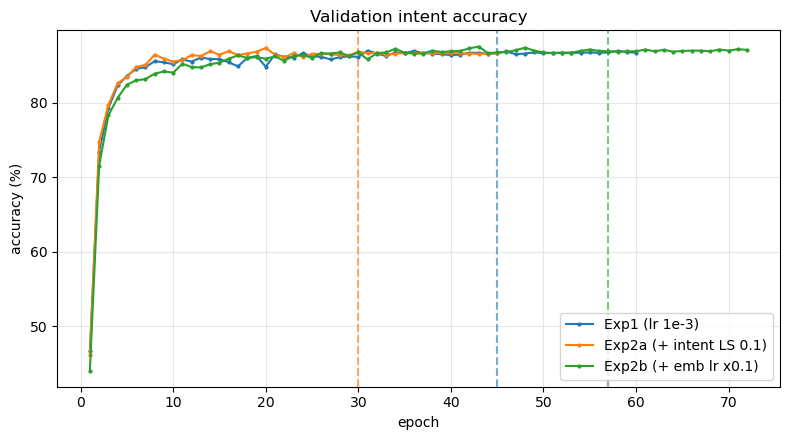

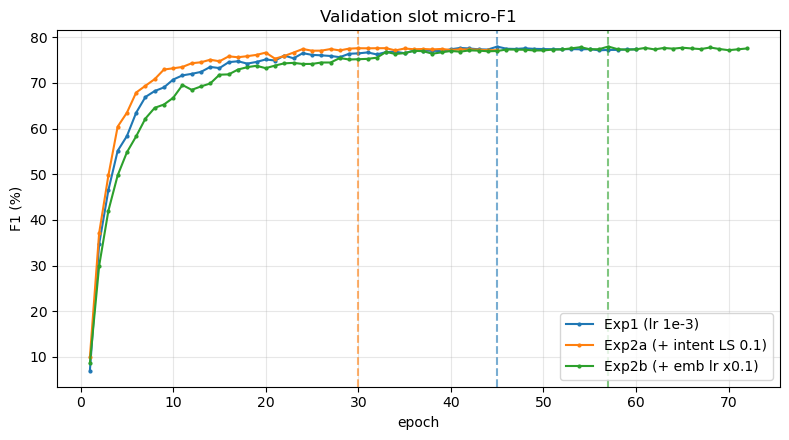

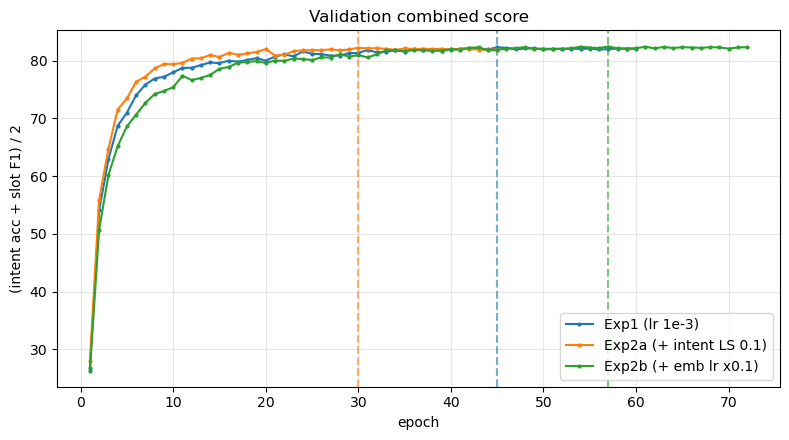

In [39]:
exp2Runs = [(hist, name, res["best_epoch"]) for name, res, hist in compareRuns[1:]]   # Exp1, 2a, 2b
plot_compare(exp2Runs, "val_intent_loss", "Validation intent loss (unsmoothed; dashed = best epoch)", "cross-entropy")
plot_compare(exp2Runs, "val_slot_loss", "Validation slot loss", "cross-entropy")
plot_compare(exp2Runs, "train_intent_loss", "Training intent loss (unsmoothed)", "cross-entropy")
plot_compare(exp2Runs, "val_intent_acc", "Validation intent accuracy", "accuracy (%)")
plot_compare(exp2Runs, "val_slot_f1", "Validation slot micro-F1", "F1 (%)")
plot_compare(exp2Runs, "val_score", "Validation combined score", "(intent acc + slot F1) / 2")

### Exp 2 follow-up: is the intent-loss rise overconfidence? (Exp 1 vs Exp 2a, validation split)

Exp 2a cut the rise in (unsmoothed) validation intent loss from +24% to +5% without changing accuracy. If that rise was caused by **over-confident mistakes**, Exp 2a's wrong predictions should carry clearly lower confidence than Exp 1's, while the number of mistakes stays about the same.

For each checkpoint we look at the softmax intent distribution on the dev set and report, for **wrong** predictions: mean / median confidence (max probability), share predicted with > 0.9 confidence, mean probability on the gold intent and mean CE; plus mean confidence on **correct** predictions and the expected calibration error (ECE, 15 equal-width bins).

validation split                         Exp1 (no smoothing)   Exp2a (intent LS 0.1)
dev intent errors                                        271                     267
intent accuracy (%)                                    86.67                   86.87
wrong: mean confidence                                 0.757                   0.570
wrong: median confidence                               0.837                   0.560
wrong: % with confidence > 0.9                          41.3                    11.6
wrong: mean prob. on gold intent                       0.076                   0.079
wrong: mean CE (unsmoothed)                            4.859                   3.490
correct: mean confidence                               0.973                   0.881
ECE (%)                                                 7.74                    3.69


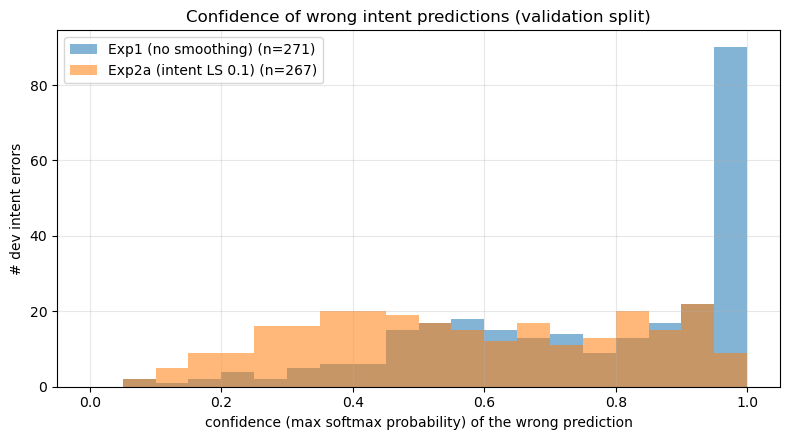

In [40]:
@torch.no_grad()
def intent_probs(model, loader):
    """Softmax intent probabilities and gold ids for a split (dropout off)."""
    model.eval()
    probs, gold = [], []
    for ids, tags, lengths, intentIds, tokens in loader:
        intentLogits, _ = model(ids.to(device), lengths.to(device))
        probs.append(torch.softmax(intentLogits, dim=-1).cpu())
        gold.append(intentIds)
    return torch.cat(probs), torch.cat(gold)

def expected_calibration_error(conf, correct, numBins=15):
    edges = torch.linspace(0, 1, numBins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        inBin = (conf > lo) & (conf <= hi)
        if inBin.any():
            ece += inBin.float().mean().item() * abs(correct[inBin].float().mean().item() - conf[inBin].mean().item())
    return 100 * ece

def confidence_report(ckptPath, buildFn, loader=devLoader):
    model = buildFn()
    model.load_state_dict(torch.load(ckptPath, map_location=device)["model_state"])
    probs, gold = intent_probs(model, loader)
    conf, pred = probs.max(-1)
    correct = pred.eq(gold)
    wrong = ~correct
    goldProb = probs.gather(1, gold.unsqueeze(1)).squeeze(1)
    return {
        "n_wrong": int(wrong.sum()),
        "acc": 100 * correct.float().mean().item(),
        "wrong_conf_mean": conf[wrong].mean().item(),
        "wrong_conf_median": conf[wrong].median().item(),
        "wrong_conf_gt_0.9_pct": 100 * (conf[wrong] > 0.9).float().mean().item(),
        "wrong_gold_prob_mean": goldProb[wrong].mean().item(),
        "wrong_ce_mean": (-goldProb[wrong].clamp_min(1e-12).log()).mean().item(),
        "correct_conf_mean": conf[correct].mean().item(),
        "ece": expected_calibration_error(conf, correct),
        "_conf_wrong": conf[wrong].numpy(),
    }

EXP1_CKPT = os.path.join(SAVE_DIR, "stage2_attn_lr1e-3_best.pt")
EXP2A_CKPT = os.path.join(SAVE_DIR, "stage2_exp2a_intent_ls0.1_best.pt")
confReports = {
    "Exp1 (no smoothing)": confidence_report(EXP1_CKPT, build_attention),
    "Exp2a (intent LS 0.1)": confidence_report(EXP2A_CKPT, build_attention),
}

rows = [("dev intent errors", "n_wrong", "{:.0f}"), ("intent accuracy (%)", "acc", "{:.2f}"),
        ("wrong: mean confidence", "wrong_conf_mean", "{:.3f}"),
        ("wrong: median confidence", "wrong_conf_median", "{:.3f}"),
        ("wrong: % with confidence > 0.9", "wrong_conf_gt_0.9_pct", "{:.1f}"),
        ("wrong: mean prob. on gold intent", "wrong_gold_prob_mean", "{:.3f}"),
        ("wrong: mean CE (unsmoothed)", "wrong_ce_mean", "{:.3f}"),
        ("correct: mean confidence", "correct_conf_mean", "{:.3f}"),
        ("ECE (%)", "ece", "{:.2f}")]
names = list(confReports)
print(f"{'validation split':<36}" + "".join(f"{n:>24}" for n in names))
for label, key, fmt in rows:
    print(f"{label:<36}" + "".join(f"{fmt.format(confReports[n][key]):>24}" for n in names))

plt.figure(figsize=(8, 4.5))
bins = np.linspace(0, 1, 21)
for n in names:
    plt.hist(confReports[n]["_conf_wrong"], bins=bins, alpha=0.55, label=f"{n} (n={confReports[n]['n_wrong']})")
plt.xlabel("confidence (max softmax probability) of the wrong prediction")
plt.ylabel("# dev intent errors")
plt.title("Confidence of wrong intent predictions (validation split)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Experiment 3: CRF slot layer with BIOES constraints

**Motivation.** Slots are currently decoded by an independent per-token argmax, and `decode_bioes` silently repairs invalid tag sequences. The dev errors are dominated by boundary / fragmentation mistakes this cannot fix (`lunch meeting` → two `event_name` spans, `desk lamp one` → `desk` + `lamp one`, `two hours from now` → `two hours`). A linear-chain CRF scores the whole tag sequence, so tag decisions are made jointly, and BIOES constraints make invalid sequences impossible.

**Two parts:**

| Run | What | Training |
|---|---|---|
| Exp 3a | BIOES-**constrained Viterbi decoding** on the Exp 2a checkpoint's per-token log-softmax scores (no learned transitions) | none — re-decodes Exp 2a |
| Exp 3b | Exp 2a + **CRF slot layer**: learned transition / start / end scores (221 × 221 + 2 × 221 ≈ 49k params) with the same BIOES constraints; slot loss = CRF negative log-likelihood | full run |

3a isolates how much comes from *only* forbidding invalid sequences; 3b adds learned tag-to-tag transitions trained jointly with the encoder.

**Kept identical to Exp 2a:** architecture up to the slot emissions, GloVe init, lr = 1e-3, intent label smoothing 0.1 (training loss only), seed, scheduler, early stopping, checkpoint rule, evaluation (`decode_bioes` + slot micro-F1). Validation split only; new checkpoint.

**Notes on the losses.**
* The CRF NLL is divided by the number of real tokens in the batch, so it is on the same per-token scale as the CE slot loss it replaces and the intent / slot balance is unchanged.
* For 3b, `val_slot_loss` is the CRF NLL per token: **not directly comparable** with the CE slot loss of Exp 1 / 2a. `val_intent_loss` is still the unsmoothed CE and stays comparable.
* BIOES constraints are applied as a large negative score (−10⁴) on forbidden transitions, in both training and decoding. Gold sequences are always valid (checked below), so this only removes impossible paths.

In [41]:
# helpers re-defined from earlier cells (identical) so Exp 3 runs after a kernel restart
# without re-running the Stage-1 test analysis or the Exp 2 comparison cells
def per_type_scores(goldAll, predAll):
    truePos, falsePos, falseNeg = Counter(), Counter(), Counter()
    for goldSlots, predSlots in zip(goldAll, predAll):
        goldCounts, predCounts = Counter(goldSlots), Counter(predSlots)
        matched = goldCounts & predCounts
        for (slotType, _), count in matched.items():
            truePos[slotType] += count
        for (slotType, _), count in (predCounts - matched).items():
            falsePos[slotType] += count
        for (slotType, _), count in (goldCounts - matched).items():
            falseNeg[slotType] += count
    rows = []
    for slotType in sorted(set(truePos) | set(falsePos) | set(falseNeg)):
        denominator = 2 * truePos[slotType] + falsePos[slotType] + falseNeg[slotType]
        f1 = 100 * 2 * truePos[slotType] / denominator if denominator else 0.0
        rows.append((slotType, f1, truePos[slotType] + falseNeg[slotType]))
    return rows

def load_run(prefix):
    with open(os.path.join(SAVE_DIR, f"{prefix}_results.json")) as f:
        res = json.load(f)
    with open(os.path.join(SAVE_DIR, f"{prefix}_history.json")) as f:
        hist = json.load(f)
    return res, hist


def bioes_constraints(tagList):
    """Allowed transitions for BIOES: returns (allowed[from, to], allowedStart[tag], allowedEnd[tag]) as bool tensors.
    O / E-x / S-x  ->  O, B-y, S-y         B-x / I-x  ->  I-x, E-x  (same slot type)"""
    parts = [("O", None) if t == "O" else tuple(t.split("-", 1)) for t in tagList]
    T = len(tagList)
    allowed = torch.zeros(T, T, dtype=torch.bool)
    for i, (p1, y1) in enumerate(parts):
        for j, (p2, y2) in enumerate(parts):
            if p1 in ("O", "E", "S"):
                allowed[i, j] = p2 in ("O", "B", "S")
            else:  # B or I: the span must continue with the same type
                allowed[i, j] = p2 in ("I", "E") and y1 == y2
    allowedStart = torch.tensor([p in ("O", "B", "S") for p, _ in parts])
    allowedEnd = torch.tensor([p in ("O", "E", "S") for p, _ in parts])
    return allowed, allowedStart, allowedEnd


class BIOESCRF(nn.Module):
    """Linear-chain CRF over the slot tags with hard BIOES constraints (batch-first)."""
    FORBIDDEN = -1e4

    def __init__(self, tagList):
        super().__init__()
        T = len(tagList)
        self.transitions = nn.Parameter(torch.zeros(T, T))   # [from, to]
        self.startScores = nn.Parameter(torch.zeros(T))
        self.endScores = nn.Parameter(torch.zeros(T))
        allowed, allowedStart, allowedEnd = bioes_constraints(tagList)
        self.register_buffer("transPenalty", (~allowed).float() * self.FORBIDDEN)
        self.register_buffer("startPenalty", (~allowedStart).float() * self.FORBIDDEN)
        self.register_buffer("endPenalty", (~allowedEnd).float() * self.FORBIDDEN)

    def _scores(self):
        return (self.transitions + self.transPenalty,
                self.startScores + self.startPenalty,
                self.endScores + self.endPenalty)

    def neg_log_likelihood(self, emissions, tags, mask):
        """Sum over the batch of -log p(gold tags | x). emissions [B,L,T], tags [B,L] (padding may be -100), mask [B,L] bool."""
        trans, start, end = self._scores()
        B, L, T = emissions.shape
        tags = tags.masked_fill(~mask, 0)
        maskF = mask.float()
        batchIdx = torch.arange(B, device=emissions.device)

        # score of the gold path
        gold = start[tags[:, 0]] + emissions[batchIdx, 0, tags[:, 0]]
        for i in range(1, L):
            step = trans[tags[:, i - 1], tags[:, i]] + emissions[batchIdx, i, tags[:, i]]
            gold = gold + step * maskF[:, i]
        lastTags = tags[batchIdx, mask.sum(1) - 1]
        gold = gold + end[lastTags]

        # log partition function (forward algorithm). logsumexp_j(alpha_j + trans_jk) is computed as a matrix
        # product in exp space (shifted by the maxima for stability): same value, much faster than a [B,T,T] logsumexp.
        # Forbidden transitions have exp(-1e4) = 0, i.e. they contribute nothing, exactly as intended.
        transMax = trans.max()
        expTrans = torch.exp(trans - transMax)
        alpha = start.unsqueeze(0) + emissions[:, 0]                                       # [B,T]
        for i in range(1, L):
            alphaMax = alpha.max(dim=1, keepdim=True).values
            nxt = (torch.log((torch.exp(alpha - alphaMax) @ expTrans).clamp_min(1e-30))
                   + alphaMax + transMax + emissions[:, i])
            alpha = torch.where(mask[:, i].unsqueeze(1), nxt, alpha)
        logZ = torch.logsumexp(alpha + end.unsqueeze(0), dim=1)
        return (logZ - gold).sum()

    @torch.no_grad()
    def viterbi_decode(self, emissions, mask):
        """Best tag sequence per utterance -> list of lists of tag ids (true length only)."""
        trans, start, end = self._scores()
        B, L, T = emissions.shape
        score = start.unsqueeze(0) + emissions[:, 0]
        identity = torch.arange(T, device=emissions.device).expand(B, T)
        backpointers = []
        for i in range(1, L):
            best, idx = (score.unsqueeze(2) + trans.unsqueeze(0)).max(dim=1)             # [B,T]
            m = mask[:, i].unsqueeze(1)
            score = torch.where(m, best + emissions[:, i], score)
            backpointers.append(torch.where(m, idx, identity))                         # padding: carry tag through
        lastTag = (score + end.unsqueeze(0)).argmax(-1)
        path = [lastTag]
        for bp in reversed(backpointers):
            lastTag = bp.gather(1, lastTag.unsqueeze(1)).squeeze(1)
            path.append(lastTag)
        path = torch.stack(path[::-1], dim=1).tolist()                                 # [B,L]
        lengths = mask.sum(1).tolist()
        return [p[:n] for p, n in zip(path, lengths)]


def lengths_to_mask(lengths, maxLen):
    return torch.arange(maxLen, device=lengths.device).unsqueeze(0) < lengths.unsqueeze(1)


# sanity check: every gold training tag sequence is allowed under the BIOES constraints
_allowed, _allowedStart, _allowedEnd = bioes_constraints(tagList)
numInvalidGold = 0
for example in encoded["train"]:
    t = example["tags"].tolist()
    ok = _allowedStart[t[0]] and _allowedEnd[t[-1]] and all(_allowed[a, b] for a, b in zip(t[:-1], t[1:]))
    numInvalidGold += not ok
print("gold training sequences violating BIOES constraints:", numInvalidGold)
assert numInvalidGold == 0


def count_invalid_sequences(predTags):
    """# predicted tag sequences (strings) that violate BIOES — these are the ones decode_bioes has to 'repair'."""
    bad = 0
    for seq in predTags:
        t = [tagToId[x] for x in seq]
        ok = _allowedStart[t[0]] and _allowedEnd[t[-1]] and all(_allowed[a, b] for a, b in zip(t[:-1], t[1:]))
        bad += not ok
    return bad


def slot_prf(goldAll, predAll):
    """Slot micro precision / recall / F1 (same matching as eval_macro_f1)."""
    tp = fp = fn = 0
    for g, p in zip(goldAll, predAll):
        gc, pc = Counter(g), Counter(p)
        m = sum((gc & pc).values())
        tp += m; fp += sum(pc.values()) - m; fn += sum(gc.values()) - m
    precision = 100 * tp / max(tp + fp, 1)
    recall = 100 * tp / max(tp + fn, 1)
    return precision, recall, 100 * 2 * tp / max(2 * tp + fp + fn, 1), tp + fp

gold training sequences violating BIOES constraints: 0


### Exp 3a: BIOES-constrained Viterbi decoding of Exp 2a (no retraining)

Re-decodes the Exp 2a checkpoint: per-token log-softmax slot scores are used as emissions, transition / start / end scores are zero, and only the BIOES constraints are active. The intent prediction is unchanged.

In [42]:
@torch.no_grad()
def predict_constrained(model, loader, crf):
    """Like predict(), but slot tags come from constrained Viterbi over log-softmax emissions."""
    model.eval()
    predIntents, predSlots, predTags = [], [], []
    for ids, tags, lengths, intentIds, tokens in loader:
        ids, lengths = ids.to(device), lengths.to(device)
        intentLogits, slotLogits = model(ids, lengths)
        predIntents += [idToIntent[i] for i in intentLogits.argmax(-1).tolist()]
        paths = crf.viterbi_decode(torch.log_softmax(slotLogits, dim=-1), lengths_to_mask(lengths, ids.size(1)))
        for utteranceTokens, path in zip(tokens, paths):
            tagSeq = [idToTag[t] for t in path]
            predTags.append(tagSeq)
            predSlots.append(decode_bioes(utteranceTokens, tagSeq))
    return {"pred_intents": predIntents, "pred_slots": predSlots, "pred_tags": predTags}

exp2aModelReloaded = build_attention()
exp2aModelReloaded.load_state_dict(torch.load(EXP2A_CKPT, map_location=device)["model_state"])
constraintOnly = BIOESCRF(tagList).to(device)          # zero transitions -> constraints only

exp3aArgmaxOut = predict(exp2aModelReloaded, devLoader)                       # Exp 2a as trained
exp3aOut = predict_constrained(exp2aModelReloaded, devLoader, constraintOnly)
exp3aMetrics = score_split(exp3aOut, encoded["dev"])
print("Exp 2a argmax       :", score_split(exp3aArgmaxOut, encoded["dev"]))
print("Exp 3a constrained  :", exp3aMetrics)
assert exp3aOut["pred_intents"] == exp3aArgmaxOut["pred_intents"]   # intent head untouched

Exp 2a argmax       : {'intent_acc': 86.87, 'slot_f1': 77.61, 'combined': 82.24}
Exp 3a constrained  : {'intent_acc': 86.87, 'slot_f1': 80.3, 'combined': 83.59}


### Exp 3b: train the joint model with a CRF slot layer

`BiLSTMAttentionCRFJoint` is the Stage-1 attention model with a `BIOESCRF` on top of the slot emissions (the forward pass is inherited unchanged). `train_model_crf` is the `train_model_s2` loop with the slot CE swapped for the CRF NLL and argmax decoding swapped for Viterbi.

In [43]:
class BiLSTMAttentionCRFJoint(BiLSTMAttentionJoint):
    def __init__(self, *args, tagList=None, **kwargs):
        super().__init__(*args, **kwargs)        # same layers and the same RNG draws as build_attention()
        self.crf = BIOESCRF(tagList)             # zero-initialised: consumes no random numbers

def build_attention_crf():
    return BiLSTMAttentionCRFJoint(len(wordToId), EMBEDDING_DIM, HIDDEN_SIZE, NUM_LAYERS,
                                   len(intentToId), len(tagToId), DROPOUT, PAD_ID,
                                   pretrained=embedding_matrix, tagList=tagList).to(device)


def crf_losses(model, intentLogits, emissions, intentIds, tags, lengths, intentSmoothing=0.0):
    """(unsmoothed intent CE, intent loss used for training, CRF NLL per real token)."""
    mask = lengths_to_mask(lengths, emissions.size(1))
    intentLoss = F.cross_entropy(intentLogits, intentIds)
    intentTrainLoss = (F.cross_entropy(intentLogits, intentIds, label_smoothing=intentSmoothing)
                       if intentSmoothing > 0 else intentLoss)
    slotLoss = model.crf.neg_log_likelihood(emissions, tags, mask) / mask.sum()
    return intentLoss, intentTrainLoss, slotLoss


@torch.no_grad()
def predict_crf(model, loader):
    """Same outputs as predict(): mean losses (intent = unsmoothed CE, slot = CRF NLL / token) + predictions."""
    model.eval()
    lossTotals = {"loss": 0.0, "intent_loss": 0.0, "slot_loss": 0.0}
    numBatches = 0
    predIntents, predSlots, predTags = [], [], []
    for ids, tags, lengths, intentIds, tokens in loader:
        ids, tags, lengths, intentIds = move_batch_to_device(ids, tags, lengths, intentIds)
        intentLogits, emissions = model(ids, lengths)
        intentLoss, _, slotLoss = crf_losses(model, intentLogits, emissions, intentIds, tags, lengths)
        lossTotals["loss"] += (intentLoss + slotLoss).item()
        lossTotals["intent_loss"] += intentLoss.item()
        lossTotals["slot_loss"] += slotLoss.item()
        numBatches += 1

        predIntents += [idToIntent[i] for i in intentLogits.argmax(-1).tolist()]
        for utteranceTokens, path in zip(tokens, model.crf.viterbi_decode(emissions, lengths_to_mask(lengths, ids.size(1)))):
            tagSeq = [idToTag[t] for t in path]
            predTags.append(tagSeq)
            predSlots.append(decode_bioes(utteranceTokens, tagSeq))
    output = {key: total / numBatches for key, total in lossTotals.items()}
    output.update(pred_intents=predIntents, pred_slots=predSlots, pred_tags=predTags)
    return output


def train_model_crf(model, ckptPath, lr, intentSmoothing=0.0, numEpochs=NUM_EPOCHS, patience=PATIENCE, tag="model"):
    """train_model_s2 with the CRF slot loss / Viterbi decoding. Same scheduler, early stopping and checkpoint rule."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    history, best, badEpochs, startTime = [], {"score": -1.0, "epoch": 0}, 0, time.time()

    for epoch in range(1, numEpochs + 1):
        epochStart = time.time()
        model.train()
        totals = {"loss": 0.0, "intent_loss": 0.0, "intent_loss_smoothed": 0.0, "slot_loss": 0.0}
        for ids, tags, lengths, intentIds, _ in trainLoader:
            ids, tags, lengths, intentIds = move_batch_to_device(ids, tags, lengths, intentIds)
            if WORD_DROPOUT > 0:
                ids = apply_word_dropout(ids)
            optimizer.zero_grad()
            intentLogits, emissions = model(ids, lengths)
            intentLoss, intentTrainLoss, slotLoss = crf_losses(model, intentLogits, emissions, intentIds, tags,
                                                                lengths, intentSmoothing)
            (intentTrainLoss + slotLoss).backward()
            clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            totals["loss"] += (intentLoss + slotLoss).item()
            totals["intent_loss"] += intentLoss.item()
            totals["intent_loss_smoothed"] += intentTrainLoss.item()
            totals["slot_loss"] += slotLoss.item()
        trainLosses = {k: v / len(trainLoader) for k, v in totals.items()}

        valOut = predict_crf(model, devLoader)
        valMetrics = score_split(valOut, encoded["dev"])
        scheduler.step(valMetrics["combined"])

        record = {
            "epoch": epoch,
            "train_loss": trainLosses["loss"],
            "train_intent_loss": trainLosses["intent_loss"],
            "train_intent_loss_smoothed": trainLosses["intent_loss_smoothed"],
            "train_slot_loss": trainLosses["slot_loss"],           # CRF NLL / token
            "val_loss": valOut["loss"],
            "val_intent_loss": valOut["intent_loss"],
            "val_slot_loss": valOut["slot_loss"],                  # CRF NLL / token
            "val_intent_acc": valMetrics["intent_acc"],
            "val_slot_f1": valMetrics["slot_f1"],
            "val_score": valMetrics["combined"],
            "lr": optimizer.param_groups[0]["lr"],
            "epoch_time": time.time() - epochStart,
            "elapsed": time.time() - startTime,
        }
        history.append(record)

        improved = valMetrics["combined"] > best["score"]
        if improved:
            best = {"score": valMetrics["combined"], "epoch": epoch, "metrics": valMetrics}
            badEpochs = 0
            torch.save({"model_state": model.state_dict(), "epoch": epoch,
                        "val_score": valMetrics["combined"], "val_metrics": valMetrics}, ckptPath)
        else:
            badEpochs += 1

        savedMarker = "  <- saved" if improved else ""
        print(f"[{tag}] epoch {epoch:3d} | train loss {record['train_loss']:.4f} | val loss {record['val_loss']:.4f} "
              f"(intent {record['val_intent_loss']:.3f}, slot CRF {record['val_slot_loss']:.3f}) | "
              f"val intent acc {valMetrics['intent_acc']:6.2f} | val slot F1 {valMetrics['slot_f1']:6.2f} | "
              f"score {valMetrics['combined']:6.2f} | lr {record['lr']:.5f} | {record['epoch_time']:.1f}s{savedMarker}")
        if badEpochs >= patience:
            print(f"early stopping: no improvement for {patience} epochs")
            break

    totalTime = time.time() - startTime
    print(f"\ntraining finished: {len(history)} epochs in {totalTime:.1f}s")
    print(f"best epoch: {best['epoch']} | best validation score: {best['score']:.2f} "
          f"(intent acc {best['metrics']['intent_acc']:.2f}, slot F1 {best['metrics']['slot_f1']:.2f}) | checkpoint: {ckptPath}")
    return history, best, totalTime

In [44]:
EXP3_SMOOTHING = 0.1          # = Exp 2a
EXP3_TAG = "Exp3b CRF + LS 0.1"
EXP3_PREFIX = "stage2_exp3b_crf_ls0.1"
EXP3_CKPT = os.path.join(SAVE_DIR, f"{EXP3_PREFIX}_best.pt")
assert EXP3_CKPT not in (BASELINE_CKPT, ATTN_CKPT, EXP1_CKPT, EXP2A_CKPT)

set_seed()
exp3Model = build_attention_crf()
exp3Total, _ = count_params(exp3Model)
print(f"total parameters: {exp3Total:,} (CRF adds {exp3Total - count_params(build_attention())[0]:,})")
assert exp3Total <= 20_000_000

set_seed()                     # re-seed so model init and data order match Exp 2a exactly
exp3Model = build_attention_crf()
exp3History, exp3Best, exp3Time = train_model_crf(exp3Model, EXP3_CKPT, lr=EXP1_LR,
                                                  intentSmoothing=EXP3_SMOOTHING, tag=EXP3_TAG)

# dev-only evaluation of the best checkpoint (reloaded into a fresh model)
exp3Model = build_attention_crf()
exp3Ckpt = torch.load(EXP3_CKPT, map_location=device)
exp3Model.load_state_dict(exp3Ckpt["model_state"])
exp3DevOut = predict_crf(exp3Model, devLoader)
exp3DevMetrics = score_split(exp3DevOut, encoded["dev"])
assert abs(exp3DevMetrics["combined"] - exp3Best["score"]) < 0.01, (exp3DevMetrics, exp3Best)

exp3Results = {
    "label": "Stage-2 Exp3b: attention + CRF (BIOES-constrained), lr=1e-3, intent label smoothing 0.1",
    "start_lr": EXP1_LR, "intent_label_smoothing": EXP3_SMOOTHING, "emb_lr_scale": 1.0,
    "total_params": exp3Total, "trainable_params": count_params(exp3Model)[1],
    "best_epoch": exp3Ckpt["epoch"], "epochs_run": len(exp3History), "train_time_s": exp3Time,
    "validation": {key: exp3DevMetrics[key] for key in ("intent_acc", "slot_f1", "combined")},
}
with open(os.path.join(SAVE_DIR, f"{EXP3_PREFIX}_results.json"), "w") as f:
    json.dump(exp3Results, f, indent=2)
with open(os.path.join(SAVE_DIR, f"{EXP3_PREFIX}_history.json"), "w") as f:
    json.dump(exp3History, f, indent=2)

total parameters: 2,637,884 (CRF adds 49,283)
[Exp3b CRF + LS 0.1] epoch   1 | train loss 4.0596 | val loss 2.1491 (intent 1.669, slot CRF 0.480) | val intent acc  59.76 | val slot F1  26.90 | score  43.33 | lr 0.00100 | 14.3s  <- saved
[Exp3b CRF + LS 0.1] epoch   2 | train loss 1.9029 | val loss 1.2316 (intent 0.897, slot CRF 0.334) | val intent acc  77.57 | val slot F1  51.95 | score  64.76 | lr 0.00100 | 14.1s  <- saved
[Exp3b CRF + LS 0.1] epoch   3 | train loss 1.3488 | val loss 0.9990 (intent 0.721, slot CRF 0.278) | val intent acc  82.05 | val slot F1  61.18 | score  71.61 | lr 0.00100 | 14.3s  <- saved
[Exp3b CRF + LS 0.1] epoch   4 | train loss 1.1165 | val loss 0.8907 (intent 0.645, slot CRF 0.246) | val intent acc  84.16 | val slot F1  67.32 | score  75.74 | lr 0.00100 | 14.1s  <- saved
[Exp3b CRF + LS 0.1] epoch   5 | train loss 0.9654 | val loss 0.8123 (intent 0.596, slot CRF 0.217) | val intent acc  85.59 | val slot F1  72.08 | score  78.84 | lr 0.00100 | 14.2s  <- saved

### Exp 3 comparison (validation split)

Slot precision / recall show *how* F1 changes (fragmenting one gold span into two predicted spans costs precision as well as recall); "invalid" counts dev utterances whose raw predicted tag sequence breaks BIOES and had to be repaired by `decode_bioes` (always 0 for Viterbi-decoded runs).

In [45]:
exp1Model_ = build_attention()
exp1Model_.load_state_dict(torch.load(EXP1_CKPT, map_location=device)["model_state"])
exp1DevOut_ = predict(exp1Model_, devLoader)

devGold = [e["gold_slots"] for e in encoded["dev"]]
exp3Compare = [
    ("Exp1 (lr 1e-3, argmax)", exp1DevOut_),
    ("Exp2a (+LS, argmax)", exp3aArgmaxOut),
    ("Exp3a (2a + constrained Viterbi)", exp3aOut),
    ("Exp3b (+ CRF, trained)", exp3DevOut),
]
print(f"{'Run (validation split)':<34}{'Intent':>8}{'SlotP':>8}{'SlotR':>8}{'SlotF1':>8}{'Comb.':>8}"
      f"{'#pred spans':>13}{'utts w/ slot err':>18}{'invalid':>9}")
print(f"{'(gold)':<34}{'':>40}{sum(len(g) for g in devGold):>13}")
for name, out in exp3Compare:
    m = score_split(out, encoded["dev"])
    p, r, f1, numPred = slot_prf(devGold, out["pred_slots"])
    numErr = sum(Counter(g) != Counter(pr) for g, pr in zip(devGold, out["pred_slots"]))
    print(f"{name:<34}{m['intent_acc']:>8.2f}{p:>8.2f}{r:>8.2f}{f1:>8.2f}{m['combined']:>8.2f}"
          f"{numPred:>13}{numErr:>18}{count_invalid_sequences(out['pred_tags']):>9}")

Run (validation split)              Intent   SlotP   SlotR  SlotF1   Comb.  #pred spans  utts w/ slot err  invalid
(gold)                                                                             2012
Exp1 (lr 1e-3, argmax)               86.67   77.23   78.73   77.97   82.32         2051               511      141
Exp2a (+LS, argmax)                  86.87   77.01   78.23   77.61   82.24         2044               518      136
Exp3a (2a + constrained Viterbi)     86.87   81.52   79.13   80.30   83.59         1953               479        0
Exp3b (+ CRF, trained)               87.06   82.18   79.77   80.96   84.01         1953               461        0


In [46]:
# per-slot-type F1: Exp 2a (argmax) vs Exp 3b (CRF), largest changes first
f1Before = {t: (f1, n) for t, f1, n in per_type_scores(devGold, exp3aArgmaxOut["pred_slots"])}
f1After = {t: (f1, n) for t, f1, n in per_type_scores(devGold, exp3DevOut["pred_slots"])}
changes = sorted(((f1After.get(t, (0, 0))[0] - f1Before.get(t, (0, 0))[0], t,
                   max(f1Before.get(t, (0, 0))[1], f1After.get(t, (0, 0))[1]))
                  for t in set(f1Before) | set(f1After)), reverse=True)
print(f"{'slot type':<24}{'#gold':>7}{'F1 2a':>8}{'F1 3b':>8}{'delta':>8}")
for k, (delta, t, n) in enumerate(changes[:8] + changes[-8:]):
    if k == 8:
        print("  ...")
    print(f"{t:<24}{n:>7}{f1Before.get(t, (0, 0))[0]:>8.1f}{f1After.get(t, (0, 0))[0]:>8.1f}{delta:>+8.1f}")

# examples that Exp 2a got wrong and Exp 3b fixes (and vice versa), fixed seed
rngEx = random.Random(SEED)
fixed = [i for i in range(len(devGold)) if Counter(devGold[i]) != Counter(exp3aArgmaxOut["pred_slots"][i])
         and Counter(devGold[i]) == Counter(exp3DevOut["pred_slots"][i])]
broken = [i for i in range(len(devGold)) if Counter(devGold[i]) == Counter(exp3aArgmaxOut["pred_slots"][i])
          and Counter(devGold[i]) != Counter(exp3DevOut["pred_slots"][i])]
print(f"\ndev utterances fixed by the CRF: {len(fixed)} | newly broken: {len(broken)}")
for title, idx in (("fixed", fixed), ("broken", broken)):
    print(f"\n{title}:")
    for i in rngEx.sample(idx, min(5, len(idx))):
        print(f"utt: {splits['dev'][i]['utt']}\n  gold: {devGold[i]}\n  2a  : {exp3aArgmaxOut['pred_slots'][i]}\n  3b  : {exp3DevOut['pred_slots'][i]}")

slot type                 #gold   F1 2a   F1 3b   delta
movie_type                    1    66.7   100.0   +33.3
change_amount                 6    54.5    72.7   +18.2
podcast_name                  8    28.6    46.2   +17.6
general_frequency            15    50.0    66.7   +16.7
email_address                 3    85.7   100.0   +14.3
radio_name                   21    46.8    60.5   +13.7
game_name                    18    66.7    78.8   +12.1
playlist_name                 7    44.4    55.6   +11.1
  ...
audiobook_author              1     0.0     0.0    +0.0
app_name                      8    85.7    85.7    +0.0
alarm_type                    2     0.0     0.0    +0.0
transport_type               54    95.6    94.7    -0.8
order_type                   19    92.3    90.5    -1.8
player_setting               36    69.7    64.7    -5.0
cooking_type                  2    50.0    40.0   -10.0
coffee_type                   2   100.0    80.0   -20.0

dev utterances fixed by the CRF: 100 | ne

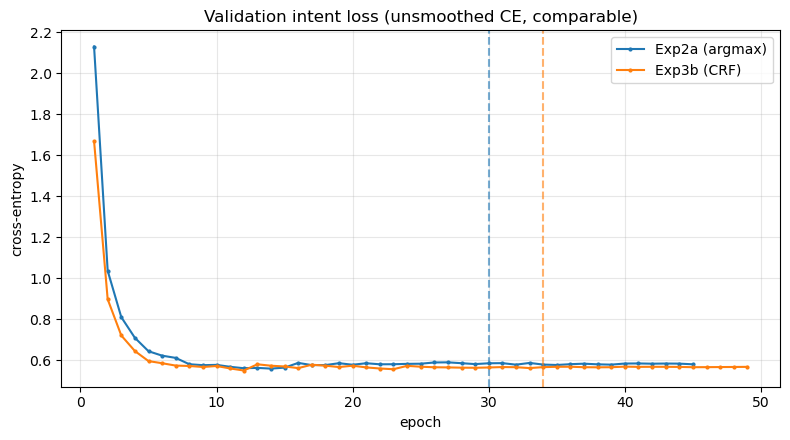

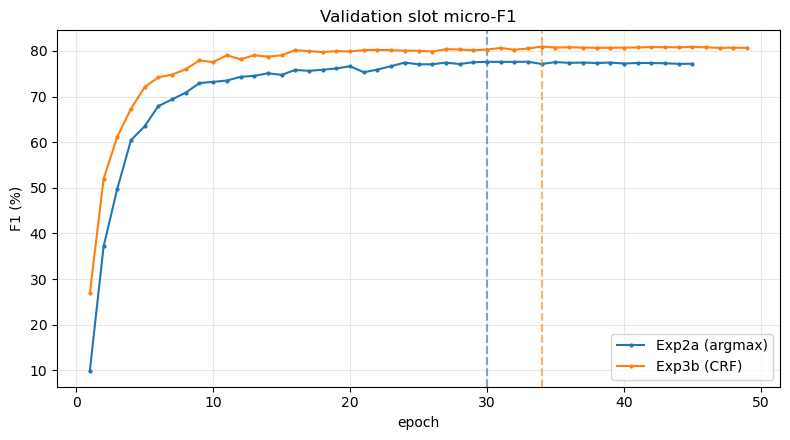

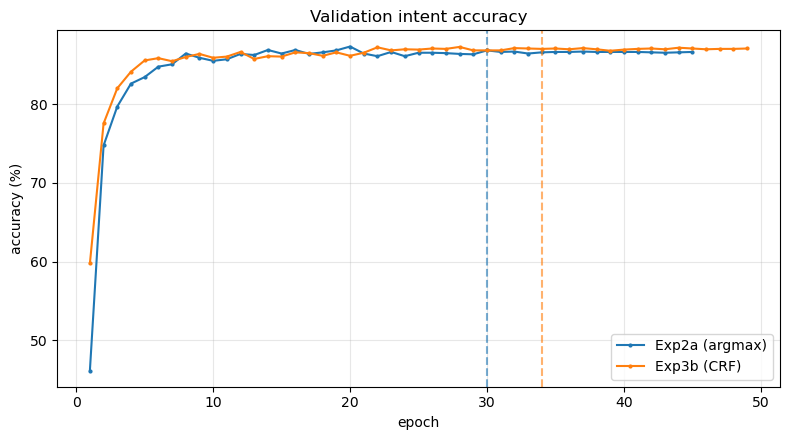

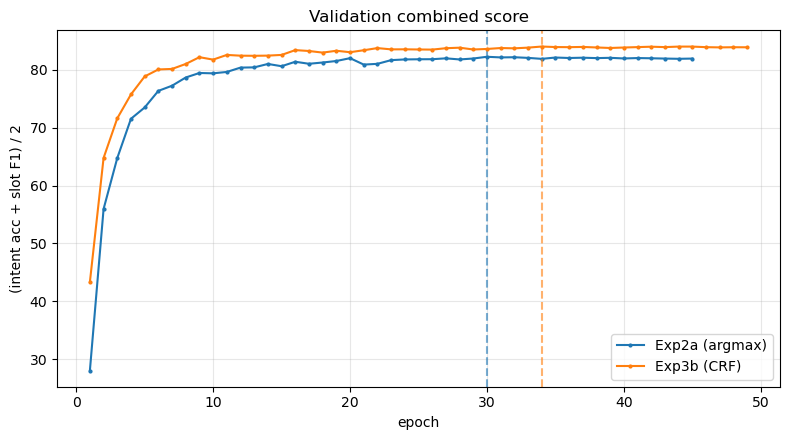

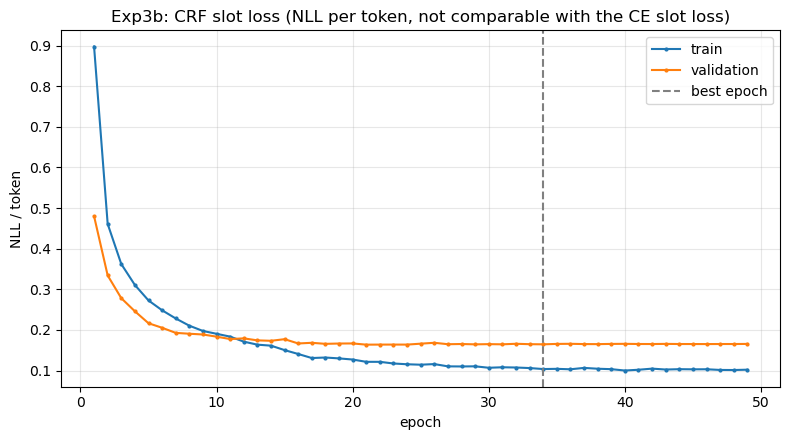

In [47]:
exp2aHist_ = load_run("stage2_exp2a_intent_ls0.1")[1]
exp3Runs = [(exp2aHist_, "Exp2a (argmax)", load_run("stage2_exp2a_intent_ls0.1")[0]["best_epoch"]),
            (exp3History, "Exp3b (CRF)", exp3Results["best_epoch"])]
plot_compare(exp3Runs, "val_intent_loss", "Validation intent loss (unsmoothed CE, comparable)", "cross-entropy")
plot_compare(exp3Runs, "val_slot_f1", "Validation slot micro-F1", "F1 (%)")
plot_compare(exp3Runs, "val_intent_acc", "Validation intent accuracy", "accuracy (%)")
plot_compare(exp3Runs, "val_score", "Validation combined score", "(intent acc + slot F1) / 2")
plt.figure(figsize=(8, 4.5))
for key, label in (("train_slot_loss", "train"), ("val_slot_loss", "validation")):
    plt.plot(get_history_values(exp3History, "epoch"), get_history_values(exp3History, key), label=label, marker="o", markersize=2)
plt.axvline(exp3Results["best_epoch"], color="gray", linestyle="--", label="best epoch")
plt.title("Exp3b: CRF slot loss (NLL per token, not comparable with the CE slot loss)")
plt.xlabel("epoch"); plt.ylabel("NLL / token"); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

---
# Stage 2 final system: Exp 3b (BiLSTM + attention + BIOES-constrained CRF, intent label smoothing 0.1)

**Selection.** Exp 3b was chosen on the **validation split only** (best combined dev score of all Stage-2 runs). No Stage-2 design decision used the test split.

**Final evaluation (this is the only time the Stage-2 system sees the test split):**
1. The Exp 3b best checkpoint is loaded into a **freshly built** `BiLSTMAttentionCRFJoint` (no further training).
2. The validation split is scored and **asserted** to reproduce the best validation score recorded during training (from the checkpoint itself, the saved results JSON and, if still in memory, `exp3Best`).
3. The test split is scored **once**.

Slot tags are decoded with **constrained Viterbi** through `predict_crf` — the same decoding used for model selection during training — not with the Stage-1 `predict()`, which takes a per-token argmax. As a check, every decoded tag sequence must satisfy the BIOES constraints.

**Stage-1 row.** The Stage-1 BiLSTM + attention validation and test scores are read from `attention_results.json`, written by the Stage-1 `final_evaluation` above, so the Stage-1 model is not run on test a second time.

*After a kernel restart, run the setup cells, the Exp 3 definition cells (`bioes_constraints` / `BIOESCRF` and `BiLSTMAttentionCRFJoint` / `predict_crf`), then the cells below. Do **not** re-run the Exp 3b training cell: it would overwrite the selected checkpoint.*

In [48]:
FINAL_PREFIX = "stage2_exp3b_crf_ls0.1"
FINAL_CKPT = os.path.join(SAVE_DIR, f"{FINAL_PREFIX}_best.pt")
FINAL_LABEL = "Stage-2 Exp3b: BiLSTM + attention + CRF (BIOES), lr=1e-3, intent LS 0.1"

def final_evaluation_crf(ckptPath, prefix, label, buildFn=None):
    """Reload the selected CRF checkpoint into a fresh model, verify dev, then score test once (Viterbi decoding)."""
    buildFn = buildFn or build_attention_crf
    model = buildFn()
    checkpoint = torch.load(ckptPath, map_location=device)
    model.load_state_dict(checkpoint["model_state"])
    totalParams, trainableParams = count_params(model)
    with open(os.path.join(SAVE_DIR, f"{prefix}_results.json")) as f:
        trainResults = json.load(f)
    with open(os.path.join(SAVE_DIR, f"{prefix}_history.json")) as f:
        history = json.load(f)
    print(f"loaded {ckptPath} (saved at epoch {checkpoint['epoch']})")

    # 1) validation: must reproduce the best validation score recorded during training
    valOut = predict_crf(model, devLoader)                      # constrained Viterbi, as in training
    valMetrics = score_split(valOut, encoded["dev"])
    references = {"checkpoint": checkpoint["val_metrics"], "results JSON": trainResults["validation"]}
    if "exp3Best" in globals():
        references["exp3Best (in memory)"] = exp3Best["metrics"]
    for source, ref in references.items():
        for key in ("intent_acc", "slot_f1", "combined"):
            assert abs(valMetrics[key] - ref[key]) < 0.01, (source, key, valMetrics, ref)
    assert checkpoint["epoch"] == trainResults["best_epoch"] == max(history, key=lambda r: r["val_score"])["epoch"]
    assert count_invalid_sequences(valOut["pred_tags"]) == 0, "decoding is not Viterbi-constrained"
    print("validation scores reproduce the best training-time score (checked against: "
          + ", ".join(references) + ")")

    # 2) test: scored exactly once, with the same Viterbi decoding
    testOut = predict_crf(model, testLoader)
    testMetrics = score_split(testOut, encoded["test"])
    assert count_invalid_sequences(testOut["pred_tags"]) == 0
    assert len(testOut["pred_intents"]) == len(encoded["test"]) == 2974

    print(f"\n{label} | total params {totalParams:,} | trainable {trainableParams:,} | "
          f"best epoch {checkpoint['epoch']} | epochs run {len(history)}")
    print(f"  VALIDATION  intent accuracy: {valMetrics['intent_acc']:.2f}% | slot micro-F1: {valMetrics['slot_f1']:.2f}%")
    print(f"  TEST        intent accuracy: {testMetrics['intent_acc']:.2f}% | slot micro-F1: {testMetrics['slot_f1']:.2f}%")

    results = {
        "label": label,
        "checkpoint": os.path.basename(ckptPath),
        "decoding": "BIOES-constrained Viterbi (CRF)",
        "total_params": totalParams,
        "trainable_params": trainableParams,
        "best_epoch": checkpoint["epoch"],
        "epochs_run": len(history),
        "train_time_s": trainResults["train_time_s"],
        "validation": {key: valMetrics[key] for key in ("intent_acc", "slot_f1")},
        "test": {key: testMetrics[key] for key in ("intent_acc", "slot_f1")},
    }
    return model, valOut, testOut, results


finalModel, finalValOut, finalTestOut, finalResults = final_evaluation_crf(FINAL_CKPT, FINAL_PREFIX, FINAL_LABEL)
with open(os.path.join(SAVE_DIR, "stage2_final_results.json"), "w") as f:
    json.dump(finalResults, f, indent=2)

loaded ../Results/stage2_exp3b_crf_ls0.1_best.pt (saved at epoch 34)
validation scores reproduce the best training-time score (checked against: checkpoint, results JSON, exp3Best (in memory))

Stage-2 Exp3b: BiLSTM + attention + CRF (BIOES), lr=1e-3, intent LS 0.1 | total params 2,637,884 | trainable 2,637,884 | best epoch 34 | epochs run 49
  VALIDATION  intent accuracy: 87.06% | slot micro-F1: 80.96%
  TEST        intent accuracy: 86.45% | slot micro-F1: 78.09%


### Final comparison: Stage 1 vs Stage 2

In [49]:
with open(os.path.join(SAVE_DIR, "attention_results.json")) as f:
    stage1Final = json.load(f)                  # written by the Stage-1 final_evaluation (its one test pass)
with open(os.path.join(SAVE_DIR, "stage2_final_results.json")) as f:
    stage2Final = json.load(f)

systems = [("Stage-1 BiLSTM + attention", stage1Final), ("Stage-2 Exp3b (+ CRF, LS)", stage2Final)]
print(f"{'Model version':<28}{'Split':<12}{'#params':>12}{'#trainable':>12}{'Intent acc':>12}{'Slot F1':>10}{'Epochs':>8}")
for name, res in systems:
    for split in ("validation", "test"):
        m = res[split]
        print(f"{name:<28}{split.capitalize():<12}{res['total_params']:>12,}{res['trainable_params']:>12,}"
              f"{m['intent_acc']:>12.2f}{m['slot_f1']:>10.2f}{res['epochs_run']:>8}")
print("-" * 94)
for split in ("validation", "test"):
    d = {k: stage2Final[split][k] - stage1Final[split][k] for k in ("intent_acc", "slot_f1")}
    print(f"{'Δ Stage 2 − Stage 1':<28}{split.capitalize():<12}"
          f"{stage2Final['total_params'] - stage1Final['total_params']:>+12,}"
          f"{stage2Final['trainable_params'] - stage1Final['trainable_params']:>+12,}"
          f"{d['intent_acc']:>+12.2f}{d['slot_f1']:>+10.2f}{stage2Final['epochs_run'] - stage1Final['epochs_run']:>+8}")
assert stage2Final["total_params"] <= 20_000_000

Model version               Split            #params  #trainable  Intent acc   Slot F1  Epochs
Stage-1 BiLSTM + attention  Validation     2,588,601   2,588,601       86.42     76.59      84
Stage-1 BiLSTM + attention  Test           2,588,601   2,588,601       85.57     73.13      84
Stage-2 Exp3b (+ CRF, LS)   Validation     2,637,884   2,637,884       87.06     80.96      49
Stage-2 Exp3b (+ CRF, LS)   Test           2,637,884   2,637,884       86.45     78.09      49
----------------------------------------------------------------------------------------------
Δ Stage 2 − Stage 1         Validation       +49,283     +49,283       +0.64     +4.37     -35
Δ Stage 2 − Stage 1         Test             +49,283     +49,283       +0.88     +4.96     -35
